# Processamento de imagens de TEM - Detecção, quantificação e mapeamento
### Identificação de nanopartículas, orientação e morfologia (adaptado do fluxo de identificação de fases e mapeamento de orientação)

## Como usar

Este notebook foi desenvolvido para o processamento e a análise de imagens de microscopia eletrônica de transmissão (TEM) 2D, como `CG_059.tif` (2048 × 2048 pixels).

O objetivo é realizar a caracterização quantitativa das nanopartículas diretamente a partir das imagens TEM, incluindo pré-processamento, segmentação, detecção, medição de propriedades morfológicas e análise da distribuição espacial das partículas.

O fluxo de processamento contempla as seguintes etapas:

| Etapa | Procedimento aplicado às imagens TEM |
| --- | --- |
| Correção de iluminação | Correção do fundo não uniforme e remoção de pixels quentes |
| Pré-processamento | Normalização de intensidade, redução de ruído e melhoria de contraste |
| Análise de frequência | Transformada rápida de Fourier (FFT) para investigar periodicidades e características de frequência espacial |
| Calibração espacial | Conversão de pixels para nanômetros utilizando a barra de escala da imagem |
| Segmentação | Identificação das nanopartículas por limiarização e métodos de segmentação |
| Detecção de partículas | Identificação e localização individual das nanopartículas |
| Refinamento dos contornos | Ajuste das regiões segmentadas e identificação dos centros de massa |
| Caracterização morfológica | Determinação de área, perímetro, diâmetro equivalente, comprimento, largura e razão de aspecto |
| Distribuição espacial | Análise das distâncias entre partículas e cálculo da função de distribuição radial $g(r)$ |
| Análise de orientação | Determinação da orientação principal das partículas e distribuição angular |
| Análise estatística | Histogramas e estatísticas de tamanho, forma, área e distribuição das nanopartículas |
| Mapas de propriedades | Geração de mapas espaciais de tamanho, densidade, orientação e distribuição das partículas |

### Passos

1. Coloque este notebook e a imagem de TEM (`CG_059.tif` ou semelhante) na mesma pasta. Os caminhos são calculados automaticamente a partir da pasta do próprio notebook. Para analisar outra imagem, basta modificar `nome_imagem` na célula de caminhos.

2. Execute as células na ordem, de cima para baixo.

3. Os principais parâmetros ajustáveis são:

- `comprimento_barra_nm` / `tamanho_pixel_nm`: calibração da escala espacial.
- `detect_params`: parâmetros de detecção e segmentação das nanopartículas.
- `regiao_nula`: região utilizada como referência para a análise da distribuição espacial.
- `parametros_scientific`: parâmetros de processamento e análise quantitativa.
- `parametros_visual`: parâmetros de visualização dos resultados.

4. As bibliotecas OpenCV (`cv2`) e scikit-image são utilizadas para o processamento e a segmentação das imagens. O OpenCV é opcional, sendo possível utilizar métodos alternativos do scikit-image quando não estiver instalado.

5. Ao final do processamento, o notebook gera imagens processadas, máscaras de segmentação, identificação individual das nanopartículas, tabelas de propriedades morfológicas, gráficos estatísticos e mapas de distribuição espacial.

>Observação: A análise é baseada exclusivamente nas imagens TEM convencionais em duas dimensões. Não são necessários dados 4D-STEM, padrões de difração, arquivos CIF, identificação de discos de Bragg ou reconstrução de mapas cristalográficos ACOM.

# Agradecimentos e ressalvas

In [1]:
# Este tutorial foi adaptado por Abraham Contreras(guzmanabraham108@gmail.com)
# para imagens de TEM 2D:

# Não está totalmente otimizado.
# Seu objetivo é mostrar que funciona e que é divertido de usar!

In [2]:
# Amostra cedida por cortesia da Jessika Nobrega, da Ilum Escola de Ciência

**Se for util para você cite:**

>#CONTRERAS, Abraham. Processamento de imagens de TEM: detecção, quantificação e mapeamento – identificação de nanopartículas, orientação e morfologia. Código computacional.

# Início

In [4]:
# Definição dos caminhos do conjunto de dados

import os
from pathlib import Path


def obter_pasta_do_notebook():
    """Retorna a pasta onde este arquivo .ipynb está salvo."""

    # VS Code
    arquivo_vscode = globals().get('__vsc_ipynb_file__')
    if arquivo_vscode:
        return Path(arquivo_vscode).resolve().parent

    # JupyterLab / Jupyter Notebook
    sessao = os.environ.get('JPY_SESSION_NAME')
    if sessao and Path(sessao).is_absolute() and Path(sessao).exists():
        return Path(sessao).resolve().parent

    # Execução como script .py
    if '__file__' in globals():
        return Path(__file__).resolve().parent

    # Diretório de trabalho atual
    return Path.cwd().resolve()


# Pasta do notebook: todas as imagens devem estar nesta mesma pasta
pasta_notebook = obter_pasta_do_notebook()
print('Pasta do notebook (e das imagens):', pasta_notebook)

# Pasta (a mesma pasta do notebook, com separador final)
file_path = str(pasta_notebook) + os.sep

# Nome da imagem de TEM. Para analisar outra imagem semelhante, troque apenas o nome.
nome_imagem = 'CG_059.tif'
filename = file_path + nome_imagem

# Outras imagens semelhantes disponíveis na mesma pasta
print('Imagens CG_*.tif* encontradas na pasta:', sorted(p.name for p in pasta_notebook.glob('CG_*.tif*')))

# Verificação do arquivo
if not os.path.isfile(filename):
    raise FileNotFoundError(
        'Imagem não encontrada: ' + filename + '\n'
        'Coloque o arquivo ' + nome_imagem + ' na mesma pasta deste notebook.'
    )
print(nome_imagem + ': encontrado')

Pasta do notebook (e das imagens): C:\JupyterLab\2-semestre\IP1\Jessika
Imagens CG_*.tif* encontradas na pasta: ['CG_059.tif', 'CG_059_DPC.tif', 'CG_059_ESPESSURA_RELATIVA.tif', 'CG_059_PLUS.tif', 'CG_059_PLUS_PLUS_PLUS_PLUS.tif', 'CG_059_PLUS_SCIENTIFIC.tif', 'CG_059_PLUS_VISUAL.tif', 'CG_059_RESTAURADA_SCIENTIFIC.tif', 'CG_059_RESTAURADA_VISUAL.tif', 'CG_059_processada.tif']
CG_059.tif: encontrado


In [5]:
# Importação das bibliotecas

import os
import time

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
from matplotlib import patches
from matplotlib.colors import hsv_to_rgb
from types import SimpleNamespace

import tifffile
import scipy
from scipy import ndimage
from scipy.signal import fftconvolve
from scipy.special import expit
from scipy.spatial.distance import pdist

import skimage
from skimage import exposure, restoration, filters, measure, segmentation, feature

# OpenCV é opcional: acelera a redução de ruído (Non-Local Means) e o CLAHE
try:
    import cv2
except ImportError:
    cv2 = None
    print('Aviso: OpenCV (cv2) não encontrado; serão usadas alternativas do scikit-image.')

# py4DSTEM é opcional neste notebook: só é usado para ler o arquivo .cif e calcular fatores de estrutura
try:
    import py4DSTEM
    print(py4DSTEM.__version__)
except ImportError:
    py4DSTEM = None
    print('Aviso: py4DSTEM não encontrado; a etapa opcional da estrutura cristalina (CIF) será ignorada.')

0.14.18


# Funções auxiliares
As células a seguir apenas definem funções (não processam a imagem).

In [6]:
# Funções auxiliares (1/3): leitura da imagem, barra de escala e máscara de validade

def ler_imagem_tem(caminho):
    """Lê um TIFF de TEM e devolve uma imagem 2D, preservando o tipo de dado original."""
    imagem = np.squeeze(tifffile.imread(str(caminho)))
    if imagem.ndim == 3 and imagem.shape[-1] in (3, 4):
        # Imagem RGB(A): converte para tons de cinza
        imagem = imagem[..., :3].mean(axis=-1).astype(imagem.dtype)
    elif imagem.ndim == 3:
        print('Aviso: o arquivo contém', imagem.shape[0], 'quadros; usando apenas o primeiro.')
        imagem = imagem[0]
    if imagem.ndim != 2:
        raise ValueError('A imagem deve ser bidimensional; forma lida: ' + str(imagem.shape))
    return imagem


def detectar_barra_de_escala(imagem, fracao_linhas=0.15, fracao_colunas=0.5):
    """
    Procura, nos cantos inferiores, o retângulo branco com a barra de escala gravada na imagem
    pelo software do microscópio. Devolve um dicionário com a caixa (r0, r1, c0, c1) e o
    comprimento da barra em pixels, ou None se nada for encontrado.
    """
    h, w = imagem.shape
    if np.issubdtype(imagem.dtype, np.integer):
        maximo = float(np.iinfo(imagem.dtype).max)
    else:
        maximo = float(np.max(imagem))
    limite_branco, limite_escuro = 0.97 * maximo, 0.25 * maximo

    r_ini = int(h * (1 - fracao_linhas))
    largura = int(w * fracao_colunas)
    for lado, (c_ini, c_fim) in (('esquerda', (0, largura)), ('direita', (w - largura, w))):
        regiao = imagem[r_ini:, c_ini:c_fim]
        branco = regiao >= limite_branco
        rotulos, n = ndimage.label(branco)
        if n == 0:
            continue
        areas = ndimage.sum(branco, rotulos, index=np.arange(1, n + 1))
        k = int(np.argmax(areas)) + 1
        if areas[k - 1] < 2000:
            continue
        fatia = ndimage.find_objects((rotulos == k).astype(int))[0]
        r0, r1 = fatia[0].start + r_ini, fatia[0].stop + r_ini
        c0, c1 = fatia[1].start + c_ini, fatia[1].stop + c_ini

        # A barra de escala é a maior sequência horizontal de pixels escuros dentro do retângulo
        escuro = imagem[r0:r1, c0:c1] <= limite_escuro
        melhor, linha = 0, 0
        for i in range(escuro.shape[0]):
            if not escuro[i].any():
                continue
            dif = np.diff(np.concatenate(([0], escuro[i].astype(np.int8), [0])))
            comprimento = int((np.flatnonzero(dif == -1) - np.flatnonzero(dif == 1)).max())
            if comprimento > melhor:
                melhor, linha = comprimento, i
        if melhor >= 30:
            return {'lado': lado, 'caixa': (r0, r1, c0, c1),
                    'comprimento_px': melhor, 'linha_barra': r0 + linha}
    return None


def construir_mascara_valida(forma, barra, margem=8):
    """Máscara booleana (True = pixel válido). Exclui o retângulo da barra de escala."""
    mascara = np.ones(forma, dtype=bool)
    if barra is not None:
        r0, r1, c0, c1 = barra['caixa']
        mascara[max(r0 - margem, 0):r1 + margem, max(c0 - margem, 0):c1 + margem] = False
    return mascara


def preencher_regiao_invalida(imagem, mascara_valida, ruido=0.0, semente=0):
    """
    Preenche a região inválida (barra de escala) com o fundo vizinho, por convolução
    normalizada em várias escalas, e adiciona ruído gaussiano com o desvio informado.
    """
    img = imagem.astype(np.float32).copy()
    if mascara_valida.all():
        return img
    invalida = ~mascara_valida
    pesos = mascara_valida.astype(np.float32)
    preenchido = np.zeros(img.shape, dtype=bool)
    # Trabalha em resolução reduzida (blocos de 8x8) para ser rápido
    f = 8
    h, w = img.shape
    hh, ww = (h // f) * f, (w // f) * f
    pequena = (img[:hh, :ww] * pesos[:hh, :ww]).reshape(hh // f, f, ww // f, f).sum(axis=(1, 3))
    peso_p = pesos[:hh, :ww].reshape(hh // f, f, ww // f, f).sum(axis=(1, 3))
    for sigma in (3, 8, 20, 50):
        num = ndimage.gaussian_filter(pequena, sigma, mode='nearest')
        den = ndimage.gaussian_filter(peso_p, sigma, mode='nearest')
        confiavel = (den > 1e-3 * f * f).astype(np.float32)
        valor = np.where(confiavel > 0, num / np.maximum(den, 1e-6), 0).astype(np.float32)
        # interpolação normalizada: valor e confiabilidade são interpolados separadamente
        valor_g = np.pad(ndimage.zoom(valor * confiavel, f, order=1), ((0, h - hh), (0, w - ww)), mode='edge')
        confiavel_g = np.pad(ndimage.zoom(confiavel, f, order=1), ((0, h - hh), (0, w - ww)), mode='edge')
        usar = invalida & ~preenchido & (confiavel_g > 0.999)
        img[usar] = (valor_g / np.maximum(confiavel_g, 1e-6))[usar]
        preenchido |= usar
    restante = invalida & ~preenchido
    if restante.any():
        img[restante] = float(np.median(img[mascara_valida]))
    if ruido > 0:
        img[invalida] += np.random.default_rng(semente).normal(0, ruido, int(invalida.sum())).astype(np.float32)
    return img

In [7]:
# Funções auxiliares (2/3): ruído, correção de fundo, pixels quentes e processamento em etapas

def estimar_ruido(imagem, mascara=None):
    """Desvio padrão do ruído (método robusto baseado no resíduo do laplaciano de 3x3)."""
    nucleo = np.array([[1, -2, 1], [-2, 4, -2], [1, -2, 1]], dtype=np.float32)
    residuo = ndimage.convolve(imagem.astype(np.float32), nucleo, mode='reflect')
    if mascara is not None:
        residuo = residuo[ndimage.binary_erosion(mascara, iterations=3)]
    mad = np.median(np.abs(residuo - np.median(residuo)))
    return float(1.4826 * mad / 6.0)


def estimar_fundo_polinomial(imagem, mascara_valida, ordem=3, fator=16, n_iter=8, k_baixo=1.5, k_alto=3.0):
    """
    Estima o fundo de iluminação (vinheta/inclinação) ajustando um polinômio 2D em resolução reduzida,
    com rejeição iterativa dos pixels do espécime (mais escuros) e de valores muito claros.
    """
    h, w = imagem.shape
    hb, wb = h // fator, w // fator
    bloco = imagem[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    val = mascara_valida[:hb * fator, :wb * fator].reshape(hb, fator, wb, fator)
    n_val = val.sum(axis=(1, 3))
    media = (bloco * val).sum(axis=(1, 3)) / np.maximum(n_val, 1)
    valido = n_val >= 0.9 * fator * fator

    def termos(yy, xx):
        return [xx ** i * yy ** j for i in range(ordem + 1) for j in range(ordem + 1 - i)]

    yy, xx = np.meshgrid((np.arange(hb) + 0.5) / hb * 2 - 1, (np.arange(wb) + 0.5) / wb * 2 - 1, indexing='ij')
    A = np.stack([t[valido] for t in termos(yy, xx)], axis=1)
    b = media[valido]
    usar = np.ones_like(b, dtype=bool)
    for _ in range(n_iter):
        coef = np.linalg.lstsq(A[usar], b[usar], rcond=None)[0]
        residuo = b - A @ coef
        sigma = 1.4826 * np.median(np.abs(residuo[usar] - np.median(residuo[usar])))
        usar = (residuo > -k_baixo * sigma) & (residuo < k_alto * sigma)
    Y, X = np.meshgrid((np.arange(h) + 0.5) / h * 2 - 1, (np.arange(w) + 0.5) / w * 2 - 1, indexing='ij')
    fundo = sum(c * t for c, t in zip(coef, termos(Y, X)))
    return fundo.astype(np.float32)


def remover_pixels_quentes(imagem, limiar_sigma=6.0, mascara=None):
    """Substitui pixels isolados muito diferentes da mediana 3x3 (raios X, pixels defeituosos)."""
    mediana = ndimage.median_filter(imagem, size=3, mode='reflect')
    residuo = imagem - mediana
    sigma = estimar_ruido(imagem, mascara)
    quentes = np.abs(residuo) > limiar_sigma * max(sigma, 1e-6)
    resultado = imagem.copy()
    resultado[quentes] = mediana[quentes]
    return resultado, int(quentes.sum())


def normalizar_percentis(imagem, percentis=(0.5, 99.7), mascara=None):
    """
    Ajusta a faixa tonal usando percentis.
    Evita que poucos pixels extremos dominem o contraste.
    """
    referencia = imagem if mascara is None else imagem[mascara]
    p_low, p_high = np.percentile(referencia, percentis)
    resultado = (imagem - p_low) / max(p_high - p_low, 1e-8)
    return np.clip(resultado, 0, 1).astype(np.float32)


def reduzir_ruido(imagem, intensidade):
    """
    Redução de ruído Non-Local Means (OpenCV). A operação é realizada em uint8.
    Sem OpenCV, usa variação total (Chambolle) como alternativa.
    """
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        resultado = cv2.fastNlMeansDenoising(imagem_uint8, None, h=float(intensidade),
                                             templateWindowSize=7, searchWindowSize=21)
        return resultado.astype(np.float32) / 255.0
    peso = 2.0 * float(intensidade) / 255.0
    return np.clip(restoration.denoise_tv_chambolle(imagem, weight=peso), 0, 1).astype(np.float32)


def aplicar_clahe(imagem, limite, grade):
    """Realce adaptativo de contraste local."""
    imagem_uint8 = np.round(np.clip(imagem, 0, 1) * 255).astype(np.uint8)
    if cv2 is not None:
        clahe = cv2.createCLAHE(clipLimit=limite, tileGridSize=grade)
        return clahe.apply(imagem_uint8).astype(np.float32) / 255.0
    h, w = imagem.shape
    return exposure.equalize_adapthist(np.clip(imagem, 0, 1), kernel_size=(h // grade[0], w // grade[1]),
                                       clip_limit=limite / 100.0).astype(np.float32)


def suavizacao_controlada(imagem, intensidade, sigma=0.7):
    """Combina a imagem com uma versão suavizada. Mantém parte da textura."""
    suavizada = ndimage.gaussian_filter(imagem, sigma)
    resultado = (1 - intensidade) * imagem + intensidade * suavizada
    return np.clip(resultado, 0, 1).astype(np.float32)


def nitidez_controlada(imagem, intensidade, sigma):
    """Unsharp Mask: realça detalhes sem substituir a imagem."""
    borrada = ndimage.gaussian_filter(imagem, sigma)
    resultado = imagem + intensidade * (imagem - borrada)
    return np.clip(resultado, 0, 1).astype(np.float32)


def equilibrar_tons(imagem, percentis=(0.2, 99.8), mascara=None):
    """Ajuste tonal final."""
    return normalizar_percentis(imagem, percentis, mascara)


def processar_imagem(imagem, parametros, mascara=None):
    """Processamento em etapas (balanço tonal -> gama -> ruído -> CLAHE -> suavização -> nitidez -> tons)."""
    dataset_balance = normalizar_percentis(imagem, (parametros['black_point'], parametros['white_point']), mascara)
    dataset_gamma = np.power(dataset_balance, parametros['gamma']).astype(np.float32)

    h_nlm = parametros['denoise_strength']
    if h_nlm == 'auto':
        # força do filtro proporcional ao ruído medido (em níveis de 0 a 255)
        h_nlm = parametros['denoise_fator'] * 255.0 * estimar_ruido(dataset_gamma, mascara)
    dataset_denoised = reduzir_ruido(dataset_gamma, h_nlm)

    dataset_clahe = aplicar_clahe(dataset_denoised, parametros['clahe_limit'], parametros['clahe_grid'])
    dataset_smooth = suavizacao_controlada(dataset_clahe, parametros['smooth_strength'], parametros['smooth_sigma'])
    dataset_sharp = nitidez_controlada(dataset_smooth, parametros['sharp_strength'], parametros['sharp_sigma'])
    dataset_final = equilibrar_tons(dataset_sharp, parametros['final_percentiles'], mascara)
    return {'balance': dataset_balance, 'gamma': dataset_gamma, 'denoised': dataset_denoised,
            'clahe': dataset_clahe, 'smooth': dataset_smooth, 'sharp': dataset_sharp,
            'final': dataset_final, 'h_nlm': float(h_nlm)}

In [8]:
# Funções auxiliares (3/3): espectro de potência, perfil radial e visualização

def espectro_de_potencia(imagem):
    """Espectro de potência (FFT centrada) com janela de Hann, para evitar artefatos de borda."""
    img = imagem.astype(np.float32) - float(imagem.mean())
    janela = np.outer(np.hanning(img.shape[0]), np.hanning(img.shape[1])).astype(np.float32)
    F = np.fft.fftshift(np.fft.fft2(img * janela))
    return np.abs(F).astype(np.float64) ** 2


def perfil_radial(array2d, centro=None):
    """Média azimutal em função do raio (em pixels) em torno do centro (linha, coluna)."""
    h, w = array2d.shape
    cy, cx = (h // 2, w // 2) if centro is None else centro
    y, x = np.indices(array2d.shape)
    r = np.hypot(y - cy, x - cx).astype(np.int32).ravel()
    soma = np.bincount(r, weights=array2d.ravel())
    cont = np.bincount(r)
    return soma / np.maximum(cont, 1)


def _comprimento_barra_agradavel(largura_nm):
    candidatos = np.array([1, 2, 5, 10, 20, 50, 100, 200, 500, 1000, 2000, 5000, 10000, 20000], dtype=float)
    return float(candidatos[np.argmin(np.abs(candidatos - 0.2 * largura_nm))])


def adicionar_barra_de_escala(eixo, pixel_nm, largura_px):
    """Desenha uma barra de escala em nm (ou µm) no canto inferior esquerdo do eixo."""
    from mpl_toolkits.axes_grid1.anchored_artists import AnchoredSizeBar
    comprimento = _comprimento_barra_agradavel(pixel_nm * largura_px)
    rotulo = f'{comprimento:g} nm' if comprimento < 1000 else f'{comprimento / 1000:g} µm'
    barra = AnchoredSizeBar(eixo.transData, comprimento / pixel_nm, rotulo, 'lower left', pad=0.5,
                            color='white', frameon=True, size_vertical=max(largura_px * 0.006, 1),
                            fontproperties=fm.FontProperties(size=10))
    barra.patch.set_facecolor('black')
    barra.patch.set_alpha(0.7)
    eixo.add_artist(barra)


def mostrar_imagens(imagens, titulos=None, cmap='gray', pixel_nm=None, tamanho=5.5, percentis=(0.5, 99.5),
                    mascara=None, barra_cor=False, titulo_geral=None, vlims=None, cmaps=None):
    """Mostra uma ou mais imagens lado a lado, com escala de cinza ajustada por percentis."""
    n = len(imagens)
    fig, eixos = plt.subplots(1, n, figsize=(tamanho * n, tamanho), squeeze=False)
    for i, (eixo, img) in enumerate(zip(eixos[0], imagens)):
        ref = img[mascara] if (mascara is not None and mascara.shape == img.shape) else img
        vmin, vmax = vlims[i] if vlims is not None else np.nanpercentile(ref, percentis)
        im = eixo.imshow(img, cmap=(cmaps[i] if cmaps else cmap), vmin=vmin, vmax=vmax)
        if titulos is not None:
            eixo.set_title(titulos[i], fontsize=12)
        if pixel_nm is not None:
            adicionar_barra_de_escala(eixo, pixel_nm, img.shape[1])
            eixo.set_xticks([]); eixo.set_yticks([])
        if barra_cor:
            plt.colorbar(im, ax=eixo, fraction=0.046, pad=0.04)
    if titulo_geral:
        fig.suptitle(titulo_geral, fontsize=14)
    plt.tight_layout()
    plt.show()
    return fig, eixos[0]

In [9]:
# Funções específicas deste notebook (1/3): escala, imagens virtuais, template e detecção

def agrupar_pixels(imagem, fator):
    """Binning (média em blocos fator x fator). Análogo ao bin_R do 4D-STEM."""
    if fator <= 1:
        return imagem
    h, w = imagem.shape
    h2, w2 = (h // fator) * fator, (w // fator) * fator
    return imagem[:h2, :w2].reshape(h2 // fator, fator, w2 // fator, fator).mean(axis=(1, 3))


def estimar_raio_caracteristico(imagem, mascara_valida, raio_min=4.0, raio_max=45.0, n_escalas=10, n_top=30, reducao=2):
    """
    Estima o raio típico dos objetos escuros pequenos (nanopartículas) por espaço-escala (LoG).
    Análogo à estimativa do raio da sonda (get_probe_size). Devolve (raio mediano, raios dos n_top melhores, posições (x, y) desses objetos).
    """
    img = agrupar_pixels(imagem, reducao)
    val = ndimage.binary_erosion(agrupar_pixels(mascara_valida.astype(np.float32), reducao) > 0.999, iterations=int(raio_max / reducao) + 2)
    sigmas = np.geomspace(raio_min, raio_max, n_escalas) / np.sqrt(2) / reducao
    pilha = np.stack([s ** 2 * ndimage.gaussian_laplace(img, s) for s in sigmas])   # positivo em manchas escuras
    pilha[:, ~val] = 0
    maximos = (pilha == ndimage.maximum_filter(pilha, size=(3, 7, 7))) & (pilha > 0)
    indices = np.argwhere(maximos)
    valores = pilha[maximos]
    melhores = np.argsort(valores)[::-1][:n_top]
    raios = sigmas[indices[melhores, 0]] * np.sqrt(2) * reducao
    posicoes = indices[melhores][:, [2, 1]] * reducao + reducao / 2.0      # (x, y) na resolução original
    return float(np.median(raios)), raios, posicoes


def nucleo_disco(raio_interno, raio_externo):
    """Núcleo normalizado de um disco (raio_interno = 0) ou de um anel."""
    n = int(np.ceil(raio_externo))
    y, x = np.mgrid[-n:n + 1, -n:n + 1]
    r = np.hypot(x, y)
    k = ((r >= raio_interno) & (r <= raio_externo)).astype(np.float32)
    return k / k.sum()


def imagem_virtual_real(imagem, modo, raios):
    """
    Imagem virtual no espaço real (análoga ao detector virtual do 4D-STEM): média da intensidade
    dentro de um disco (modo='circle', raios=raio) ou de um anel (modo='annulus', raios=(r_in, r_out))
    em torno de cada pixel.
    """
    if modo == 'circle':
        nucleo = nucleo_disco(0.0, raios)
    elif modo == 'annulus':
        nucleo = nucleo_disco(raios[0], raios[1])
    else:
        raise ValueError("modo deve ser 'circle' ou 'annulus'")
    return fftconvolve(imagem, nucleo, mode='same').astype(np.float32)


def remover_objetos_pequenos(mascara, area_min):
    """Remove componentes conexos com área menor que area_min (em pixels)."""
    rotulos, n = ndimage.label(mascara)
    if n == 0:
        return mascara
    areas = ndimage.sum(mascara, rotulos, index=np.arange(1, n + 1))
    return np.concatenate(([False], areas >= area_min))[rotulos]


def estimar_intensidade_fundo(imagem, mascara):
    """Intensidade do fundo (I0): pico mais claro do histograma da imagem."""
    contagem, bordas = np.histogram(imagem[mascara], bins=256)
    contagem = ndimage.uniform_filter1d(contagem.astype(float), 5)
    centros = 0.5 * (bordas[:-1] + bordas[1:])
    candidatos = [i for i in range(1, 255) if contagem[i] >= contagem[i - 1] and contagem[i] >= contagem[i + 1]
                  and contagem[i] > 0.3 * contagem.max()]
    return float(centros[candidatos[-1]]) if candidatos else float(np.percentile(imagem[mascara], 95))


def mascara_especime(imagem, mascara_valida, sigma=10.0, area_min=5000):
    """Máscara do espécime (regiões escuras grandes): suavização, limiar de Otsu e limpeza morfológica."""
    suave = ndimage.gaussian_filter(imagem, sigma)
    limiar = filters.threshold_otsu(suave[mascara_valida])
    mascara = (suave < limiar) & mascara_valida
    mascara = remover_objetos_pequenos(mascara, area_min)
    mascara = ndimage.binary_fill_holes(mascara)
    return mascara


def construir_template(sinal, centros, raio, mascara_valida, n_max=25, fator_janela=4.0):
    """
    Template (sonda de vácuo, análogo) = média alinhada (centro de massa) de partículas isoladas.
    centros: lista de (x, y) ordenada da melhor para a pior resposta.
    """
    L = int(np.ceil(fator_janela * raio))
    h, w = sinal.shape
    patches_ok = []
    centros = np.asarray(centros, dtype=float)
    for (x, y) in centros:
        xi, yi = int(round(x)), int(round(y))
        if xi - L < 0 or yi - L < 0 or xi + L + 1 > w or yi + L + 1 > h:
            continue
        if not mascara_valida[yi - L:yi + L + 1, xi - L:xi + L + 1].all():
            continue
        dist = np.hypot(centros[:, 0] - x, centros[:, 1] - y)
        if np.sum(dist < 3 * raio) > 1:          # apenas partículas isoladas
            continue
        recorte = sinal[yi - L:yi + L + 1, xi - L:xi + L + 1].astype(np.float32)
        yy, xx = np.mgrid[-L:L + 1, -L:L + 1]
        disco = np.hypot(xx, yy) <= 1.5 * raio
        pesos = np.clip(recorte, 0, None) * disco
        if pesos.sum() <= 0:
            continue
        cx, cy = (pesos * xx).sum() / pesos.sum(), (pesos * yy).sum() / pesos.sum()
        patches_ok.append(ndimage.shift(recorte, (-cy, -cx), order=1, mode='nearest'))
        if len(patches_ok) >= n_max:
            break
    if not patches_ok:
        raise RuntimeError('Nenhuma partícula isolada foi encontrada para construir o template; reduza o raio ou use outra imagem.')
    return np.mean(patches_ok, axis=0), len(patches_ok)


def criar_kernel(template, raio, radii=(0.0, 4.0), bilinear=True):
    """
    Kernel de correlação: template multiplicado por uma janela sigmoidal radial (1 no centro, 0 fora)
    e com média zero (análogo ao probe.get_kernel(mode='sigmoid')). Normalizado em norma L2.
    """
    n = template.shape[0] // 2
    y, x = np.mgrid[-n:n + 1, -n:n + 1]
    r = np.hypot(x, y)
    r0, r1 = radii[0] * raio, radii[1] * raio
    janela = expit((0.5 * (r0 + r1) - r) * 8.0 / max(r1 - r0, 1e-3))
    kernel = janela * (template - (janela * template).sum() / janela.sum())
    return (kernel / np.linalg.norm(kernel)).astype(np.float32)


def detectar_picos(imagem, kernel, mascara_valida=None, corrPower=1.0, sigma=2.0, edgeBoundary=10,
                   minRelativeIntensity=0.05, minAbsoluteIntensity=0.0, minPeakSpacing=15,
                   subpixel='multicorr', upsample_factor=8, maxNumPeaks=1000):
    """
    Detecção de picos por correlação cruzada com o kernel (análogo ao find_Bragg_disks).
    Devolve (dicionário com x, y e intensidade, mapa de correlação).
    """
    h, w = imagem.shape
    kh, kw = kernel.shape
    preenchido = np.zeros((h, w), dtype=np.float32)
    preenchido[:kh, :kw] = kernel
    preenchido = np.roll(preenchido, (-(kh // 2), -(kw // 2)), axis=(0, 1))
    cc = np.fft.rfft2(imagem - imagem.mean()) * np.conj(np.fft.rfft2(preenchido))
    if corrPower != 1:
        amplitude = np.abs(cc)
        cc = np.where(amplitude > 0, cc / np.maximum(amplitude, 1e-20) ** (1.0 - corrPower), 0)
    corr = np.fft.irfft2(cc, s=(h, w)).astype(np.float32)
    if sigma > 0:
        corr = ndimage.gaussian_filter(corr, sigma)

    valido = np.ones((h, w), dtype=bool) if mascara_valida is None else ndimage.binary_erosion(mascara_valida, iterations=max(int(kh // 2), 1))
    eb = int(edgeBoundary)
    valido[:eb, :] = False; valido[-eb:, :] = False; valido[:, :eb] = False; valido[:, -eb:] = False
    corr_valida = np.where(valido, corr, 0)

    janela = 2 * int(minPeakSpacing) + 1
    maximos = (corr_valida == ndimage.maximum_filter(corr_valida, size=janela)) & valido
    limiar = max(minAbsoluteIntensity, minRelativeIntensity * float(corr_valida.max()))
    ys, xs = np.nonzero(maximos & (corr_valida > limiar))
    ordem = np.argsort(corr_valida[ys, xs])[::-1][:int(maxNumPeaks)]
    ys, xs = ys[ordem], xs[ordem]

    px, py = xs.astype(float), ys.astype(float)
    for i, (yi, xi) in enumerate(zip(ys, xs)):
        if yi < 2 or xi < 2 or yi > h - 3 or xi > w - 3:
            continue
        if subpixel == 'poly':
            for eixo in (0, 1):
                a, b, c = (corr[yi - 1, xi], corr[yi, xi], corr[yi + 1, xi]) if eixo == 0 else (corr[yi, xi - 1], corr[yi, xi], corr[yi, xi + 1])
                den = a - 2 * b + c
                if den != 0:
                    delta = 0.5 * (a - c) / den
                    if eixo == 0: py[i] += np.clip(delta, -1, 1)
                    else: px[i] += np.clip(delta, -1, 1)
        elif subpixel == 'multicorr':
            pequeno = corr[yi - 2:yi + 3, xi - 2:xi + 3]
            grande = ndimage.zoom(pequeno, upsample_factor, order=3)
            iy, ix = np.unravel_index(np.argmax(grande), grande.shape)
            passo = 4.0 / (grande.shape[0] - 1)
            py[i], px[i] = yi - 2 + iy * passo, xi - 2 + ix * passo
    return {'x': px, 'y': py, 'intensidade': corr_valida[ys, xs]}, corr

In [10]:
# Funções específicas deste notebook (2/3): refinamento, pares de partículas e distribuição radial

def refinar_centros_com(sinal, picos, raio):
    """
    Refina o centro de cada partícula pelo centro de massa (CoM) local e mede o contraste, o raio equivalente
    e o fundo local (análogo ao measure_origin com findcenter='CoM').
    """
    h, w = sinal.shape
    n = int(np.ceil(3 * raio))
    yy, xx = np.mgrid[-n:n + 1, -n:n + 1]
    rr = np.hypot(xx, yy)
    saida = {k: [] for k in ('x', 'y', 'deslocamento', 'contraste', 'raio_eq', 'fundo', 'intensidade')}
    for x0, y0, inten in zip(picos['x'], picos['y'], picos['intensidade']):
        xi, yi = int(round(x0)), int(round(y0))
        if xi - n < 0 or yi - n < 0 or xi + n + 1 > w or yi + n + 1 > h:
            continue
        janela = sinal[yi - n:yi + n + 1, xi - n:xi + n + 1]
        anel = (rr >= 2.0 * raio) & (rr <= 3.0 * raio)
        fundo = float(np.median(janela[anel]))
        local = janela - fundo
        cx, cy = x0 - xi, y0 - yi
        for _ in range(3):
            disco = np.hypot(xx - cx, yy - cy) <= 1.5 * raio
            pesos = np.clip(local, 0, None) * disco
            if pesos.sum() <= 0:
                break
            cx, cy = (pesos * xx).sum() / pesos.sum(), (pesos * yy).sum() / pesos.sum()
        pico = float(local[np.hypot(xx - cx, yy - cy) <= raio].max())
        regiao = (local >= 0.5 * pico) & (np.hypot(xx - cx, yy - cy) <= 2.0 * raio)
        saida['x'].append(xi + cx); saida['y'].append(yi + cy)
        saida['deslocamento'].append(float(np.hypot(xi + cx - x0, yi + cy - y0)))
        saida['contraste'].append(float(local[np.hypot(xx - cx, yy - cy) <= raio].mean()))
        saida['raio_eq'].append(float(np.sqrt(regiao.sum() / np.pi)))
        saida['fundo'].append(fundo); saida['intensidade'].append(float(inten))
    return {k: np.array(v) for k, v in saida.items()}


def ajustar_plano(x, y, z):
    """Ajusta o plano z = a*x + b*y + c por mínimos quadrados. Devolve (coeficientes, resíduos)."""
    A = np.column_stack([x, y, np.ones_like(x)])
    coef = np.linalg.lstsq(A, z, rcond=None)[0]
    return coef, z - A @ coef


def mapa_de_pares(x, y, r_max, passo=2.0):
    """Histograma 2D dos vetores entre pares de partículas (análogo ao mapa de vetores de Bragg, BVM)."""
    dx = x[:, None] - x[None, :]
    dy = y[:, None] - y[None, :]
    usar = (np.hypot(dx, dy) < r_max) & ~np.eye(len(x), dtype=bool)
    n = int(2 * r_max / passo)
    H, _, _ = np.histogram2d(dy[usar], dx[usar], bins=n, range=[[-r_max, r_max]] * 2)
    return H


def distribuicao_radial(x, y, regiao_nula, bordas, n_sim=200, semente=0):
    """
    Função de distribuição radial g(r) das partículas, normalizada por simulações de distribuição
    aleatória uniforme (CSR) dentro da região informada. Devolve (g, g_inferior, g_superior):
    o envelope de 95% da distribuição aleatória fica em torno de 1.
    """
    rng = np.random.default_rng(semente)
    exp, _ = np.histogram(pdist(np.column_stack([x, y])), bins=bordas)
    pontos = np.argwhere(regiao_nula)
    sims = []
    for _ in range(n_sim):
        idx = rng.choice(len(pontos), size=len(x), replace=False)
        sims.append(np.histogram(pdist(pontos[idx][:, ::-1].astype(float)), bins=bordas)[0])
    sims = np.array(sims, dtype=float)
    media = np.maximum(sims.mean(axis=0), 1e-9)
    lo, hi = np.percentile(sims, (2.5, 97.5), axis=0)
    return exp / media, lo / media, hi / media

In [11]:
# Funções específicas deste notebook (3/3): segmentação, casamento de elipses e tensor de estrutura

def segmentar_particulas(imagem, mascara_valida, sigma=8.0, area_min=20000, distancia_min=60):
    """Segmenta as partículas grandes (limiar de Otsu + watershed para separar partículas encostadas)."""
    especime = mascara_especime(imagem, mascara_valida, sigma=sigma, area_min=area_min)
    distancia = ndimage.distance_transform_edt(especime)
    distancia = ndimage.gaussian_filter(distancia, 5)
    rotulos_bin, _ = ndimage.label(especime)
    sementes = feature.peak_local_max(distancia, min_distance=int(distancia_min), labels=rotulos_bin, exclude_border=False)
    marcadores = np.zeros(imagem.shape, dtype=np.int32)
    for i, (yy, xx) in enumerate(sementes, start=1):
        marcadores[yy, xx] = i
    rotulos = segmentation.watershed(-distancia, marcadores, mask=especime)
    for r in measure.regionprops(rotulos):
        if r.area < area_min:
            rotulos[rotulos == r.label] = 0
    rotulos, _, _ = segmentation.relabel_sequential(rotulos)
    return rotulos


def elipse_por_area(forma, centro, area, razao, angulo):
    """Máscara booleana de uma elipse de área e razão de aspecto dados (centro = (x, y); ângulo em rad)."""
    a = np.sqrt(area * razao / np.pi)
    b = np.sqrt(area / (np.pi * razao))
    y, x = np.indices(forma)
    c, s = np.cos(angulo), np.sin(angulo)
    u = (x - centro[0]) * c + (y - centro[1]) * s
    v = -(x - centro[0]) * s + (y - centro[1]) * c
    return (u / a) ** 2 + (v / b) ** 2 <= 1.0


def casar_elipse(mascara, passo_angulo=3.0, razoes=None, reducao_max=128):
    """
    Casamento da máscara de uma partícula com uma biblioteca de elipses (análogo ao casamento com a
    biblioteca de orientações do ACOM). A correlação é o índice de Jaccard (IoU).
    Devolve (angulo_rad, razao, iou, curva_iou_vs_angulo, angulos).
    """
    razoes = np.arange(1.0, 3.01, 0.1) if razoes is None else razoes
    f = max(1, int(np.ceil(max(mascara.shape) / reducao_max)))
    m = mascara[::f, ::f]
    area = float(m.sum())
    cy, cx = ndimage.center_of_mass(m)
    angulos = np.deg2rad(np.arange(0, 180, passo_angulo))
    iou = np.zeros((len(razoes), len(angulos)))
    for i, q in enumerate(razoes):
        for j, ang in enumerate(angulos):
            e = elipse_por_area(m.shape, (cx, cy), area, q, ang)
            iou[i, j] = np.logical_and(e, m).sum() / max(np.logical_or(e, m).sum(), 1)
    i, j = np.unravel_index(np.argmax(iou), iou.shape)
    return float(angulos[j]), float(razoes[i]), float(iou[i, j]), iou[i], angulos


def tensor_de_estrutura(imagem, sigma_grad=2.0, sigma_int=12.0):
    """Tensor de estrutura local: componentes normalizadas, orientação dominante e coerência."""
    gx = ndimage.gaussian_filter(imagem, sigma_grad, order=(0, 1))
    gy = ndimage.gaussian_filter(imagem, sigma_grad, order=(1, 0))
    Jxx = ndimage.gaussian_filter(gx * gx, sigma_int)
    Jyy = ndimage.gaussian_filter(gy * gy, sigma_int)
    Jxy = ndimage.gaussian_filter(gx * gy, sigma_int)
    tr = np.maximum(Jxx + Jyy, 1e-12)
    return {'exx': Jxx / tr - 0.5, 'eyy': Jyy / tr - 0.5, 'exy': Jxy / tr,
            'theta': 0.5 * np.arctan2(2 * Jxy, Jxx - Jyy),
            'coerencia': np.sqrt((Jxx - Jyy) ** 2 + 4 * Jxy ** 2) / tr, 'energia': tr}


def roda_de_cores_orientacao(tamanho=200):
    """Legenda de cores para orientações no plano (período de 180 graus)."""
    y, x = np.mgrid[-1:1:complex(tamanho), -1:1:complex(tamanho)]
    r = np.hypot(x, y)
    angulo = (np.arctan2(-y, x) % np.pi) / np.pi
    rgb = hsv_to_rgb(np.dstack([angulo, np.ones_like(r), np.ones_like(r)]))
    rgb[r > 1] = 1.0
    return rgb

In [12]:
# Definição da correção de campo plano (flatfield)

# Opção 1 (padrão): estimar o fundo de iluminação da própria imagem (polinômio 2D que ignora o espécime)
# Opção 2: usar uma imagem de flatfield medida, na mesma pasta (ex.: 'FF_FAU_192.tif')
usar_flatfield_externo = False

# # Pasta
ff_file_path = file_path

# # Nome do arquivo
flat_field = ff_file_path + 'FF_FAU_192.tif'

# Ordem do polinômio do fundo (Opção 1)
ordem_polinomio = 3

# Carregamento dos dados e visualização básica

In [13]:
# Carregamento do conjunto de dados

imagem_raw = ler_imagem_tem(filename)            # a imagem original nunca é modificada
imagem_original = imagem_raw.astype(np.float32)

# Dimensão da imagem (equivalente à dimensão do escaneamento 4D STEM)
scan_height, scan_width = imagem_raw.shape

print('Imagem:', nome_imagem)
print('Dimensões:', imagem_raw.shape)
print('Tipo de dado:', imagem_raw.dtype)
print('Mínimo:', imagem_raw.min(), '| Máximo:', imagem_raw.max(), '| Média: %.2f' % imagem_original.mean())

Imagem: CG_059.tif
Dimensões: (2048, 2048)
Tipo de dado: uint8
Mínimo: 0 | Máximo: 255 | Média: 135.66


Barra de escala detectada: 346 pixels  ->  200 nm
Tamanho do pixel: 0.5780 nm/pixel  (campo de visão: 1184 nm)
Desvio padrão do ruído estimado: 13.10 níveis de cinza


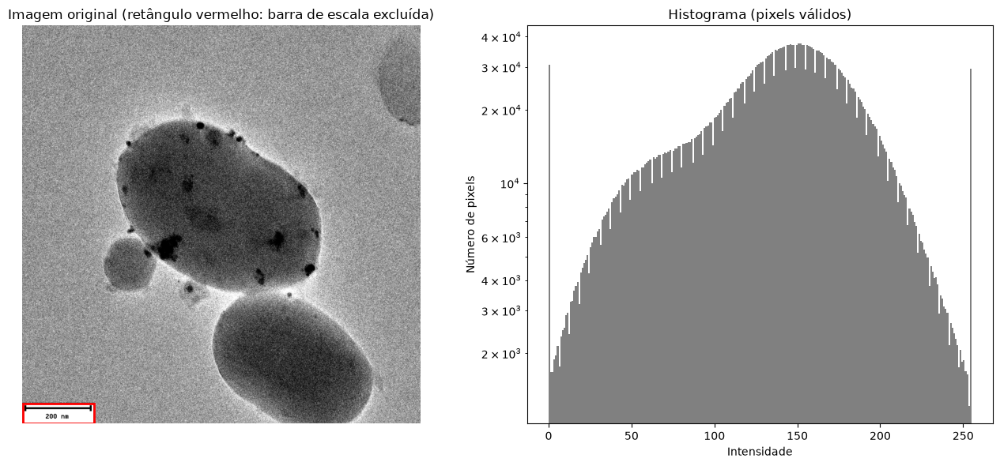

In [14]:
# Barra de escala gravada na imagem, calibração e máscara de validade

comprimento_barra_nm = 200.0    # valor escrito na barra de escala da imagem (nm)
tamanho_pixel_nm = None         # se informado (nm/pixel), substitui a calibração automática pela barra

barra = detectar_barra_de_escala(imagem_raw)
if barra is not None:
    print('Barra de escala detectada: %d pixels  ->  %.0f nm' % (barra['comprimento_px'], comprimento_barra_nm))
    if tamanho_pixel_nm is None:
        tamanho_pixel_nm = comprimento_barra_nm / barra['comprimento_px']
else:
    print('Aviso: barra de escala não detectada. Informe tamanho_pixel_nm para calibrar; sem isso, as escalas serão em pixels.')
if tamanho_pixel_nm is not None:
    print('Tamanho do pixel: %.4f nm/pixel  (campo de visão: %.0f nm)' % (tamanho_pixel_nm, tamanho_pixel_nm * scan_width))

# A região da barra de escala é excluída das estatísticas e preenchida com o fundo vizinho
mascara_valida = construir_mascara_valida(imagem_raw.shape, barra)
ruido_medido = estimar_ruido(imagem_original, mascara_valida)
dataset = preencher_regiao_invalida(imagem_raw, mascara_valida, ruido=ruido_medido)
print('Desvio padrão do ruído estimado: %.2f níveis de cinza' % ruido_medido)

fig, eixos = plt.subplots(1, 2, figsize=(13, 6))
eixos[0].imshow(imagem_raw, cmap='gray')
if barra is not None:
    r0, r1, c0, c1 = barra['caixa']
    eixos[0].add_patch(patches.Rectangle((c0, r0), c1 - c0, r1 - r0, fill=False, edgecolor='r', linewidth=2))
eixos[0].set_title('Imagem original (retângulo vermelho: barra de escala excluída)')
eixos[0].axis('off')
eixos[1].hist(imagem_raw[mascara_valida].ravel(), bins=256, color='gray')
eixos[1].set_yscale('log')
eixos[1].set_xlabel('Intensidade'); eixos[1].set_ylabel('Número de pixels'); eixos[1].set_title('Histograma (pixels válidos)')
plt.tight_layout(); plt.show()

Pixels quentes corrigidos: 1979


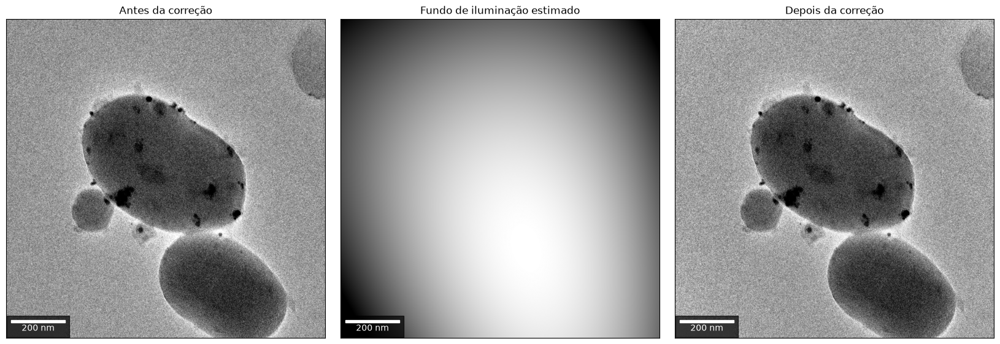

(<Figure size 1650x550 with 3 Axes>,
 array([<Axes: title={'center': 'Antes da correção'}>,
        <Axes: title={'center': 'Fundo de iluminação estimado'}>,
        <Axes: title={'center': 'Depois da correção'}>], dtype=object))

In [15]:
# Remoção de pixels quentes e correção de campo plano (flatfield)

# Pixels quentes (raios X, pixels defeituosos)
dataset, n_quentes = remover_pixels_quentes(dataset, limiar_sigma=6.0, mascara=mascara_valida)
print('Pixels quentes corrigidos:', n_quentes)

# Campo plano
if usar_flatfield_externo:
    flatfield = tifffile.imread(flat_field).astype('float32')
    if flatfield.shape != dataset.shape:
        raise ValueError('O flatfield deve ter a mesma dimensão da imagem: ' + str(flatfield.shape) + ' != ' + str(dataset.shape))
    fundo = flatfield
else:
    fundo = estimar_fundo_polinomial(dataset, mascara_valida, ordem=ordem_polinomio)

dataset_sem_flat = dataset.copy()
dataset = dataset / fundo * fundo[mascara_valida].mean()
dataset_flat = dataset.copy()

mostrar_imagens([dataset_sem_flat, fundo, dataset_flat],
                ['Antes da correção', 'Fundo de iluminação estimado', 'Depois da correção'],
                pixel_nm=tamanho_pixel_nm, mascara=mascara_valida, tamanho=5.5)

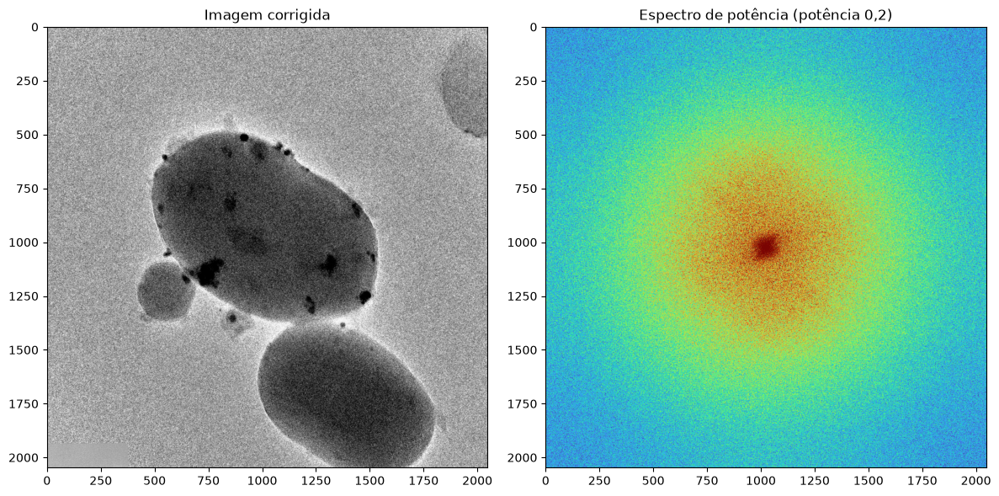

(<Figure size 1200x600 with 2 Axes>,
 array([<Axes: title={'center': 'Imagem corrigida'}>,
        <Axes: title={'center': 'Espectro de potência (potência 0,2)'}>],
       dtype=object))

In [16]:
# Calcula o espectro de potência médio (análogo ao padrão de difração médio)
dp_mean = espectro_de_potencia(dataset)

# plota a imagem corrigida e o espectro de potência
mostrar_imagens(
    [dataset, dp_mean ** 0.2],
    ['Imagem corrigida', 'Espectro de potência (potência 0,2)'],
    cmaps=['gray', 'turbo'],
    mascara=mascara_valida,
    tamanho=6,
)

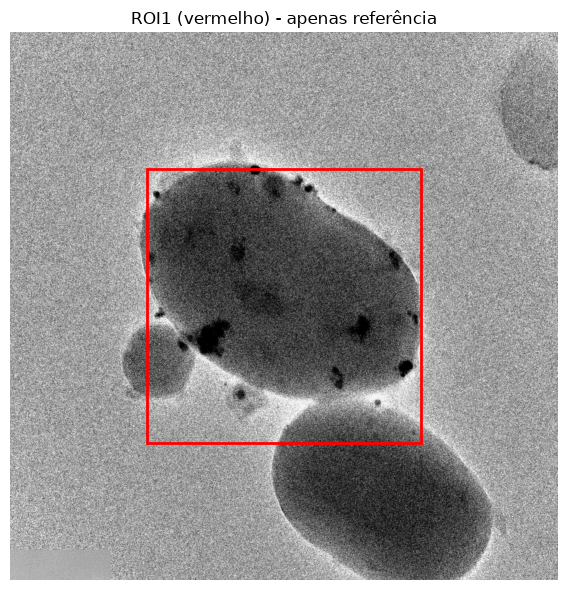

Dimensões do conjunto analisado: (2048, 2048)
Tamanho do pixel: 0.5780 nm


In [17]:
# Redução do conjunto de dados (binning, recorte)

# ROI1 = (linha_min, linha_max, coluna_min, coluna_max), em pixels da imagem original
ROI1 = (scan_height // 4, 3 * scan_height // 4, scan_width // 4, 3 * scan_width // 4)

# Neste notebook a imagem inteira é analisada por padrão (para detectar todas as partículas).
# Para analisar apenas a ROI1, use aplicar_recorte = True.
aplicar_recorte = False

# Fator de binning
R_bin_factor = 1

dataset_backup = dataset.copy()
recorte = (slice(ROI1[0], ROI1[1]), slice(ROI1[2], ROI1[3])) if aplicar_recorte else (slice(None), slice(None))
dataset = agrupar_pixels(dataset_backup[recorte], R_bin_factor)
mascara_roi = agrupar_pixels(mascara_valida[recorte].astype(np.float32), R_bin_factor) > 0.999
tamanho_pixel_roi = tamanho_pixel_nm * R_bin_factor if tamanho_pixel_nm is not None else None

fig, eixo = plt.subplots(figsize=(6, 6))
eixo.imshow(dataset_backup, cmap='gray', vmin=np.percentile(dataset_backup, 0.5), vmax=np.percentile(dataset_backup, 99.5))
eixo.add_patch(patches.Rectangle((ROI1[2], ROI1[0]), ROI1[3] - ROI1[2], ROI1[1] - ROI1[0], fill=False, edgecolor='r', linewidth=2))
eixo.set_title('ROI1 (vermelho)' + (' - aplicada' if aplicar_recorte else ' - apenas referência')); eixo.axis('off')
plt.tight_layout(); plt.show()

print('Dimensões do conjunto analisado:', dataset.shape)
if tamanho_pixel_roi is not None:
    print('Tamanho do pixel: %.4f nm' % tamanho_pixel_roi)

In [18]:
# Salva o conjunto reduzido (desative o comentário se quiser gravar)
# tifffile.imwrite(
#     os.path.splitext(filename)[0] + '_binr' + str(R_bin_factor) + '.tif',
#     dataset.astype(np.float32),
# )

# Pré-processamento em etapas (perfis SCIENTIFIC e VISUAL)
Equilíbrio tonal, gama, redução de ruído Non-Local Means, CLAHE, suavização controlada, nitidez e ajuste tonal final.
- **SCIENTIFIC**: preserva a informação estrutural (usado nas medidas).
- **VISUAL**: suavidade e destaque dos contornos (usado nas figuras).

In [19]:
# Parâmetros - Versão A: SCIENTIFIC
parametros_scientific = {
    'black_point': 0.3,
    'white_point': 99.7,
    'gamma': 0.98,

    'denoise_strength': 'auto',   # 'auto' = proporcional ao ruído medido (ou um valor fixo de h)
    'denoise_fator': 0.6,

    'clahe_limit': 1.0,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.05,
    'smooth_sigma': 0.6,

    'sharp_strength': 0.25,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.1, 99.9),
}

# Parâmetros - Versão B: VISUAL
parametros_visual = {
    'black_point': 0.5,
    'white_point': 99.7,
    'gamma': 0.95,

    'denoise_strength': 'auto',
    'denoise_fator': 1.0,

    'clahe_limit': 1.5,
    'clahe_grid': (8, 8),

    'smooth_strength': 0.15,
    'smooth_sigma': 0.8,

    'sharp_strength': 0.40,
    'sharp_sigma': 1.0,

    'final_percentiles': (0.2, 99.8),
}

Força do filtro Non-Local Means (h): scientific = 7.95 | visual = 13.14
Versão SCIENTIFIC | média = 0.5167 | desvio padrão = 0.2306 | mín = 0.000 | máx = 1.000
Versão VISUAL | média = 0.5137 | desvio padrão = 0.2450 | mín = 0.000 | máx = 1.000


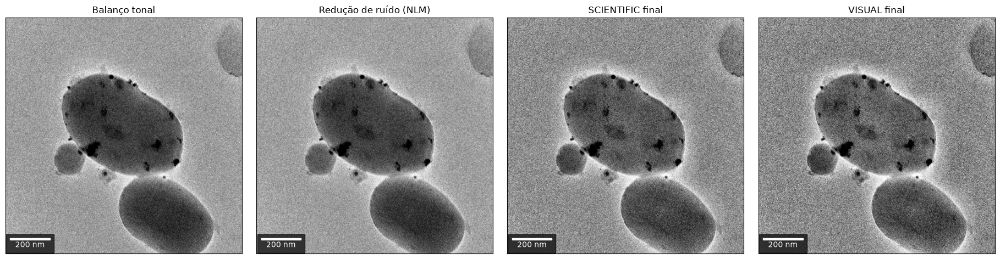

(<Figure size 1840x460 with 4 Axes>,
 array([<Axes: title={'center': 'Balanço tonal'}>,
        <Axes: title={'center': 'Redução de ruído (NLM)'}>,
        <Axes: title={'center': 'SCIENTIFIC final'}>,
        <Axes: title={'center': 'VISUAL final'}>], dtype=object))

In [20]:
# Execução das duas versões

resultados_scientific = processar_imagem(dataset, parametros_scientific, mascara_roi)
resultados_visual = processar_imagem(dataset, parametros_visual, mascara_roi)

dataset_norm = resultados_scientific['balance']
dataset_balance = resultados_scientific['balance']
dataset_gamma = resultados_scientific['gamma']
dataset_denoised = resultados_scientific['denoised']
dataset_eq = resultados_scientific['clahe']
dataset_clahe = resultados_scientific['clahe']
dataset_smooth = resultados_scientific['smooth']
dataset_sharp = resultados_scientific['sharp']

dataset_scientific = resultados_scientific['final']
dataset_visual = resultados_visual['final']

print('Força do filtro Non-Local Means (h): scientific = %.2f | visual = %.2f' % (resultados_scientific['h_nlm'], resultados_visual['h_nlm']))
for nome, img in (('SCIENTIFIC', dataset_scientific), ('VISUAL', dataset_visual)):
    print('Versão', nome, '| média = %.4f | desvio padrão = %.4f | mín = %.3f | máx = %.3f' % (img.mean(), img.std(), img.min(), img.max()))

mostrar_imagens([dataset_norm, dataset_denoised, dataset_scientific, dataset_visual],
                ['Balanço tonal', 'Redução de ruído (NLM)', 'SCIENTIFIC final', 'VISUAL final'],
                pixel_nm=tamanho_pixel_roi, vlims=[(0, 1)] * 4, tamanho=4.6)

In [21]:
# Imagem linear sem ruído e imagem de sinal (as medidas usam intensidades, sem gama nem CLAHE)

escala_lin = 1.0 / np.percentile(dataset, 99.9)
linear = reduzir_ruido(np.clip(dataset * escala_lin, 0, 1), resultados_scientific['h_nlm']) / escala_lin

# I0 = intensidade do fundo; o sinal é positivo onde a imagem é mais escura que o fundo (partículas)
I0 = estimar_intensidade_fundo(linear, mascara_roi)
sinal = (I0 - linear).astype(np.float32)
print('Intensidade do fundo (I0): %.2f' % I0)

Intensidade do fundo (I0): 155.66


# Calibração

Raio típico = 11.7 pixels (6.8 nm)


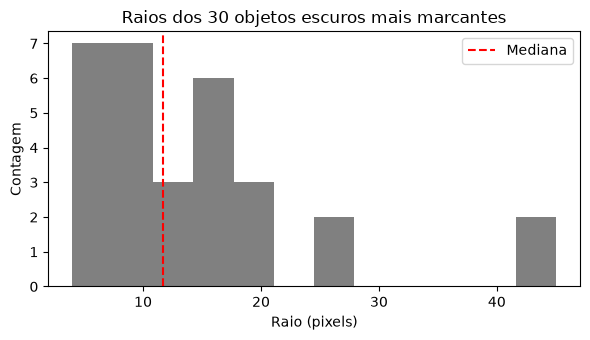

In [22]:
# Estima o raio típico das nanopartículas por espaço-escala (análogo ao raio da sonda)
# Limites de busca (em pixels): ajuste se as partículas de interesse forem menores ou maiores
raio_min_busca, raio_max_busca = 4.0, 45.0

probe_radius_pixels, raios_top, centros_LoG = estimar_raio_caracteristico(
    linear, mascara_roi, raio_min=raio_min_busca, raio_max=raio_max_busca,
)
if tamanho_pixel_roi is not None:
    print('Raio típico = %.1f pixels (%.1f nm)' % (probe_radius_pixels, probe_radius_pixels * tamanho_pixel_roi))
else:
    print('Raio típico = %.1f pixels' % probe_radius_pixels)

plt.figure(figsize=(6, 3.5))
plt.hist(raios_top, bins=12, color='gray')
plt.axvline(probe_radius_pixels, color='r', linestyle='--', label='Mediana')
plt.xlabel('Raio (pixels)'); plt.ylabel('Contagem'); plt.title('Raios dos 30 objetos escuros mais marcantes'); plt.legend()
plt.tight_layout(); plt.show()

In [23]:
# calibração do tamanho de pixel no espaço real - a partir da barra de escala da imagem
# calibração no espaço de Fourier - a partir do tamanho do campo de visão
calibracao = {
    'R_pixel_size': tamanho_pixel_roi if tamanho_pixel_roi is not None else 1.0,
    'R_pixel_units': 'nm' if tamanho_pixel_roi is not None else 'px',
}
calibracao['Q_pixel_size'] = 1.0 / (dataset.shape[1] * calibracao['R_pixel_size'])
calibracao['Q_pixel_units'] = 'nm^-1' if tamanho_pixel_roi is not None else 'px^-1'
print(calibracao)

{'R_pixel_size': 0.5780346820809249, 'R_pixel_units': 'nm', 'Q_pixel_size': 0.0008447265624999999, 'Q_pixel_units': 'nm^-1'}


# Imagens virtuais
### Faixas de BF (disco) e ADF (anel) no espaço real

In [24]:
# Cálculo das imagens virtuais de campo claro e de campo escuro

# expande o raio em 5 pixels para separar o disco central do anel
expand_BF = 5.0

radius_BF = probe_radius_pixels
radii_DF = (probe_radius_pixels + expand_BF, 3 * probe_radius_pixels + expand_BF)

bright_field = imagem_virtual_real(linear, 'circle', radius_BF)
dark_field = imagem_virtual_real(linear, 'annulus', radii_DF)

# Contraste centro-periferia: positivo onde o disco é mais escuro que o anel ao redor (nanopartículas)
contraste_centro_periferia = dark_field - bright_field

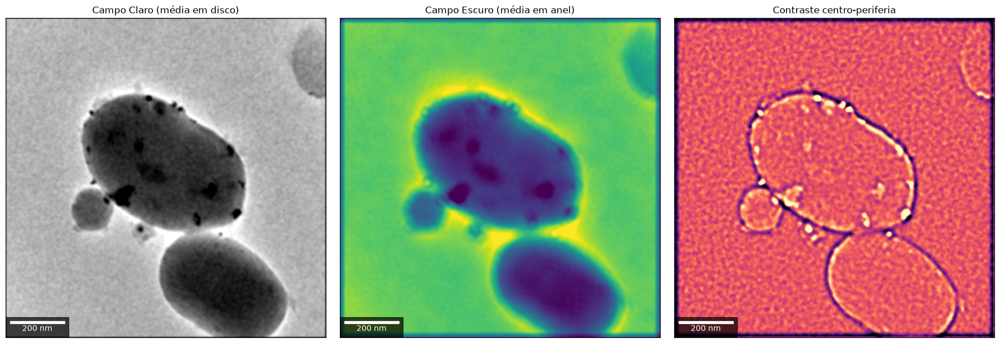

(<Figure size 1800x600 with 3 Axes>,
 array([<Axes: title={'center': 'Campo Claro (média em disco)'}>,
        <Axes: title={'center': 'Campo Escuro (média em anel)'}>,
        <Axes: title={'center': 'Contraste centro-periferia'}>],
       dtype=object))

In [25]:
# plota as imagens virtuais
mostrar_imagens(
    [bright_field, dark_field, contraste_centro_periferia],
    ['Campo Claro (média em disco)', 'Campo Escuro (média em anel)', 'Contraste centro-periferia'],
    cmaps=['gray', 'viridis', 'magma'],
    pixel_nm=tamanho_pixel_roi,
    mascara=mascara_roi,
    tamanho=6,
)

# Imagem de realce e detecção das nanopartículas

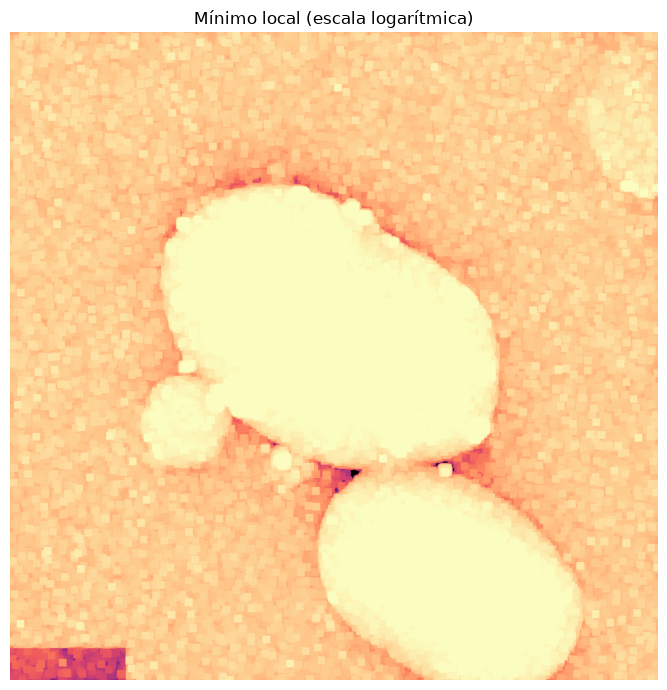

In [26]:
# visualiza os dados: mínimo local (análogo ao padrão de difração máximo), em escala logarítmica
dp_max = ndimage.minimum_filter(linear, size=int(2 * probe_radius_pixels) + 1)
fig, ax = plt.subplots(figsize=(7, 7))
ax.imshow(np.log1p(np.clip(I0 - dp_max, 0, None)), cmap='magma')
ax.set_title('Mínimo local (escala logarítmica)'); ax.axis('off')
plt.tight_layout(); plt.show()

# fig.savefig(os.path.splitext(filename)[0]+'min_local.png')

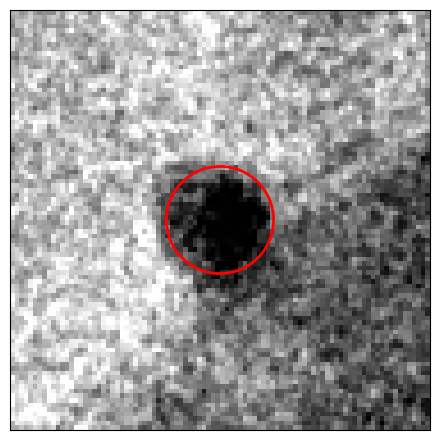

Raio estimado da partícula = 11.73 pixels


In [27]:
# Estima o raio e o centro da partícula mais marcante
probe_semiangle = probe_radius_pixels
probe_qx0, probe_qy0 = centros_LoG[0]
center = (probe_qx0, probe_qy0)

# plota a região em torno dela, com o raio estimado sobreposto como um círculo
L = int(4 * probe_semiangle)
x0, y0 = int(probe_qx0), int(probe_qy0)
recorte_p = (slice(max(y0 - L, 0), y0 + L), slice(max(x0 - L, 0), x0 + L))
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(linear[recorte_p], cmap='gray', extent=(recorte_p[1].start, recorte_p[1].stop, recorte_p[0].stop, recorte_p[0].start))
ax.add_patch(patches.Circle(center, probe_semiangle, fill=False, edgecolor='r', linewidth=2))
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

# Imprime o raio estimado da partícula
print('Raio estimado da partícula =', '%.2f' % probe_semiangle, 'pixels')

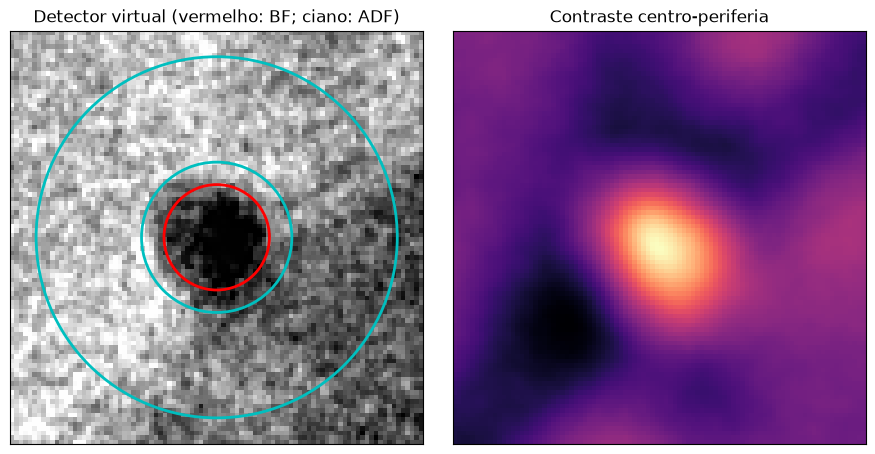

In [28]:
# Cria uma imagem virtual de campo escuro anular (ADF) ao redor da partícula

radii = (probe_semiangle + expand_BF, 3 * probe_semiangle + expand_BF)

# Plota o detector ADF (círculo de campo claro e anel de campo escuro)
fig, eixos = plt.subplots(1, 2, figsize=(9, 4.5))
ext = (recorte_p[1].start, recorte_p[1].stop, recorte_p[0].stop, recorte_p[0].start)
eixos[0].imshow(linear[recorte_p], cmap='gray', extent=ext)
eixos[0].add_patch(patches.Circle(center, probe_semiangle, fill=False, edgecolor='r', linewidth=2))
for raio_i in radii:
    eixos[0].add_patch(patches.Circle(center, raio_i, fill=False, edgecolor='c', linewidth=2))
eixos[0].set_title('Detector virtual (vermelho: BF; ciano: ADF)')
# Plota a imagem ADF (contraste centro-periferia) na mesma região
eixos[1].imshow(contraste_centro_periferia[recorte_p], cmap='magma', extent=ext)
eixos[1].set_title('Contraste centro-periferia')
for e in eixos: e.set_xticks([]); e.set_yticks([])
plt.tight_layout(); plt.show()

In [29]:
# Como as partículas isoladas são poucas, a sonda de vácuo (template) é a média alinhada de até 25 delas
probe_template, n_usadas = construir_template(sinal, centros_LoG, probe_semiangle, mascara_roi, n_max=25)
probe = SimpleNamespace(template=probe_template)
print('Template construído com', n_usadas, 'partículas isoladas')

Template construído com 20 partículas isoladas


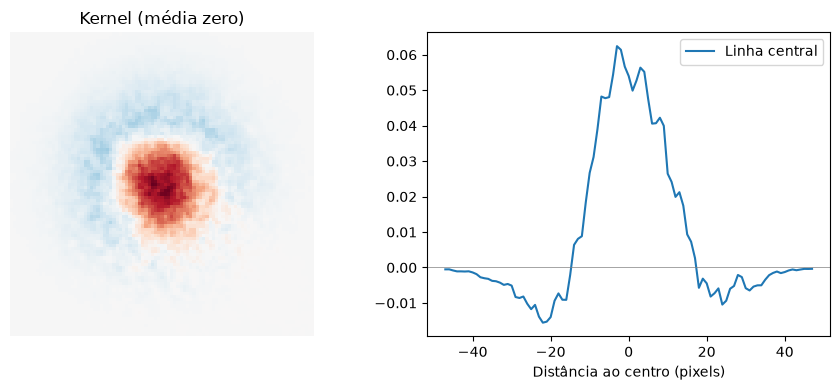

In [30]:
# Subtrai uma função de normalização para que o template tenha valor médio zero
probe.kernel = criar_kernel(
    probe.template,
    probe_semiangle,
    radii = (0.0, 4.0),        # em unidades do raio estimado
    bilinear = True,
)

# probe.kernel = ...gaussiano (alternativa): usar apenas uma gaussiana de sigma = probe_semiangle

# Plota o kernel da sonda
fig, eixos = plt.subplots(1, 2, figsize=(9, 4))
eixos[0].imshow(probe.kernel, cmap='RdBu_r', vmin=-np.abs(probe.kernel).max(), vmax=np.abs(probe.kernel).max())
eixos[0].set_title('Kernel (média zero)'); eixos[0].axis('off')
centro_k = probe.kernel.shape[0] // 2
eixos[1].plot(np.arange(-centro_k, centro_k + 1), probe.kernel[centro_k], label='Linha central')
eixos[1].axhline(0, color='gray', linewidth=0.5); eixos[1].set_xlabel('Distância ao centro (pixels)'); eixos[1].legend()
plt.tight_layout(); plt.show()

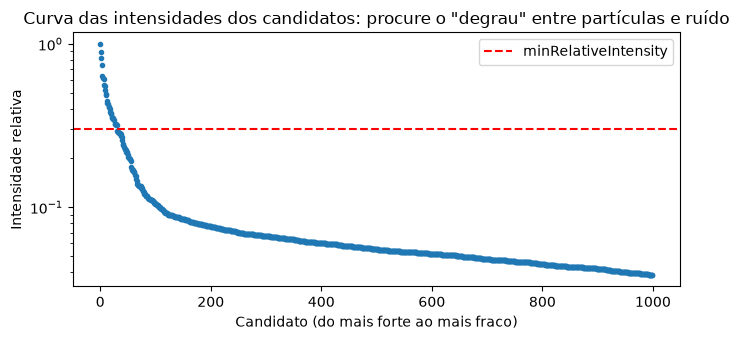

Partículas detectadas: 31


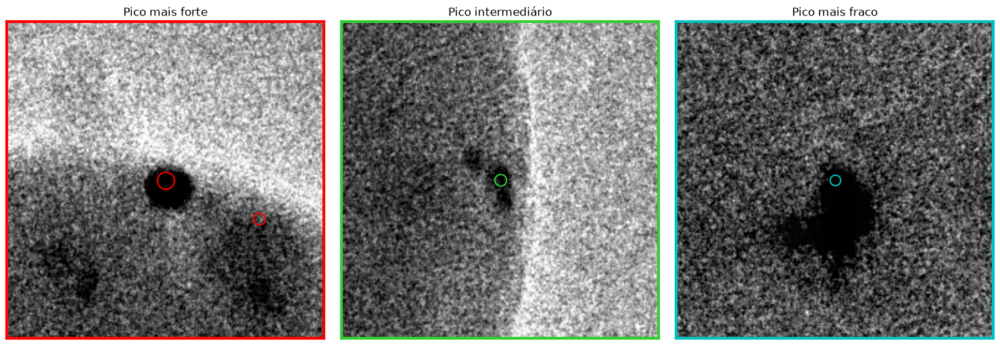

In [31]:
# Testa os parâmetros em algumas partículas
# Visualiza a imagem e as posições das partículas localizadas

# parâmetros
detect_params = {
    'corrPower': 1,
    'sigma': 2,
    'edgeBoundary': 10,
    'minRelativeIntensity': 0.3,     # fração da correlação máxima; veja a curva abaixo para ajustar
    'minAbsoluteIntensity': 0,
    'minPeakSpacing': int(round(1.5 * probe_semiangle)),
    # 'subpixel' : 'poly',
    'subpixel' : 'multicorr',
    'upsample_factor': 8,
    'maxNumPeaks': 1000,
    # 'CUDA': True,    (não se aplica: a correlação é feita por FFT na CPU)
}

# Todos os candidatos (sem limiar relativo) para visualizar onde o limiar separa objetos reais do ruído
candidatos, corr_mapa = detectar_picos(
    sinal,
    probe.kernel,
    mascara_valida = mascara_roi,
    **{**detect_params, 'minRelativeIntensity': 0.0},
)
intensidade_rel = candidatos['intensidade'] / candidatos['intensidade'].max()

plt.figure(figsize=(7, 3.5))
plt.semilogy(np.sort(intensidade_rel)[::-1], 'o', markersize=3)
plt.axhline(detect_params['minRelativeIntensity'], color='r', linestyle='--', label='minRelativeIntensity')
plt.xlabel('Candidato (do mais forte ao mais fraco)'); plt.ylabel('Intensidade relativa'); plt.legend()
plt.title('Curva das intensidades dos candidatos: procure o "degrau" entre partículas e ruído')
plt.tight_layout(); plt.show()

selecionados = intensidade_rel >= detect_params['minRelativeIntensity']
picos_teste = {k: v[selecionados] for k, v in candidatos.items()}
print('Partículas detectadas:', len(picos_teste['x']))

# Janelas de teste centradas no pico mais forte, em um intermediário e no mais fraco
ordem_int = np.argsort(picos_teste['intensidade'])[::-1]
escolhidos = [ordem_int[0], ordem_int[len(ordem_int) // 2], ordem_int[-1]]
janela_teste = 256
colors = ['r', 'limegreen', 'c']

fig, eixos = plt.subplots(1, 3, figsize=(15, 5))
for eixo, k, cor in zip(eixos, escolhidos, colors):
    cx, cy = picos_teste['x'][k], picos_teste['y'][k]
    x_ini = int(np.clip(cx - janela_teste // 2, 0, dataset.shape[1] - janela_teste))
    y_ini = int(np.clip(cy - janela_teste // 2, 0, dataset.shape[0] - janela_teste))
    eixo.imshow(linear[y_ini:y_ini + janela_teste, x_ini:x_ini + janela_teste], cmap='gray',
                extent=(x_ini, x_ini + janela_teste, y_ini + janela_teste, y_ini))
    dentro = ((picos_teste['x'] >= x_ini) & (picos_teste['x'] < x_ini + janela_teste) &
              (picos_teste['y'] >= y_ini) & (picos_teste['y'] < y_ini + janela_teste))
    eixo.scatter(picos_teste['x'][dentro], picos_teste['y'][dentro], s=300 * picos_teste['intensidade'][dentro] / picos_teste['intensidade'].max() + 30,
                 facecolors='none', edgecolors=cor, linewidths=1.5)
    for lado in eixo.spines.values():
        lado.set_edgecolor(cor); lado.set_linewidth(3)
    eixo.set_xticks([]); eixo.set_yticks([])
eixos[0].set_title('Pico mais forte'); eixos[1].set_title('Pico intermediário'); eixos[2].set_title('Pico mais fraco')
plt.tight_layout(); plt.show()

# Localização das nanopartículas em toda a imagem

Partículas detectadas: 31


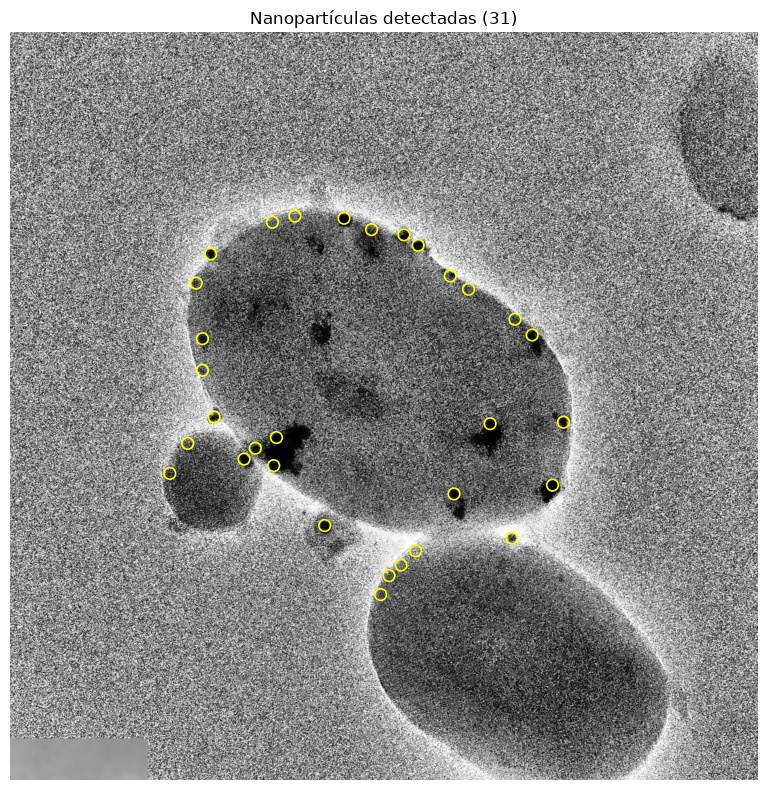

In [32]:
picos, corr_mapa = detectar_picos(
    sinal,
    probe.kernel,
    mascara_valida = mascara_roi,
    **detect_params,
)
bragg_peaks = picos      # nome mantido do fluxo original: lista de posições detectadas
print('Partículas detectadas:', len(picos['x']))

fig, eixo = plt.subplots(figsize=(8, 8))
eixo.imshow(dataset_visual, cmap='gray', vmin=0, vmax=1)
eixo.scatter(picos['x'], picos['y'], s=70, facecolors='none', edgecolors='yellow', linewidths=1.2)
eixo.set_title('Nanopartículas detectadas (' + str(len(picos['x'])) + ')'); eixo.axis('off')
plt.tight_layout(); plt.show()

# Centralização e calibração

Partículas medidas: 31
Deslocamento médio do refinamento: 5.33 pixels (máx. 11.03)


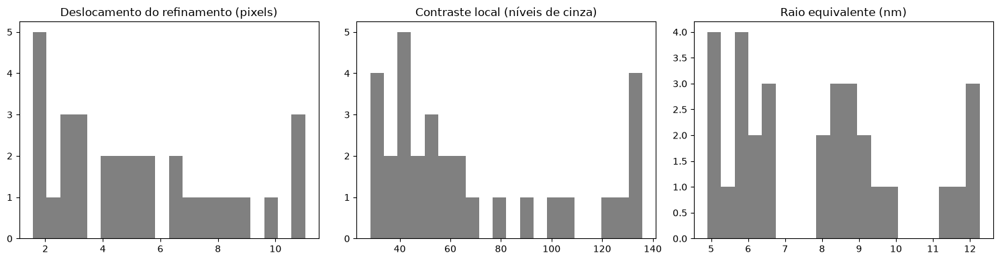

In [33]:
# Refina o centro de cada partícula (centro de massa) e mede contraste, raio equivalente e fundo local

# mede as origens
particulas = refinar_centros_com(sinal, picos, probe_semiangle)
qxy_origins = np.column_stack([particulas['x'], particulas['y']])

print('Partículas medidas:', len(particulas['x']))
print('Deslocamento médio do refinamento: %.2f pixels (máx. %.2f)' % (particulas['deslocamento'].mean(), particulas['deslocamento'].max()))

fig, eixos = plt.subplots(1, 3, figsize=(15, 4))
eixos[0].hist(particulas['deslocamento'], bins=20, color='gray'); eixos[0].set_title('Deslocamento do refinamento (pixels)')
eixos[1].hist(particulas['contraste'], bins=20, color='gray'); eixos[1].set_title('Contraste local (níveis de cinza)')
fator_nm = tamanho_pixel_roi if tamanho_pixel_roi is not None else 1.0
eixos[2].hist(particulas['raio_eq'] * fator_nm, bins=20, color='gray')
eixos[2].set_title('Raio equivalente (' + ('nm' if tamanho_pixel_roi is not None else 'pixels') + ')')
plt.tight_layout(); plt.show()

Inclinação do nível local: 3.50e-03 níveis/pixel em x, 7.97e-03 em y | desvio dos resíduos: 41.35


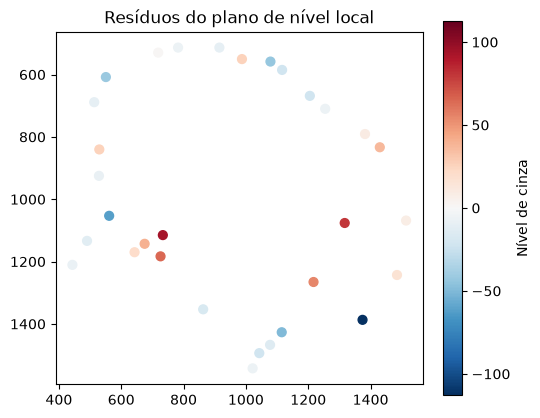

In [34]:
# ajusta um plano ao nível de fundo local ao redor das partículas (depende de elas estarem sobre o espécime ou sobre o fundo)
coef_plano, residuos_plano = ajustar_plano(particulas['x'], particulas['y'], particulas['fundo'])
qx0_fit, qy0_fit = coef_plano[0], coef_plano[1]
print('Inclinação do nível local: %.2e níveis/pixel em x, %.2e em y | desvio dos resíduos: %.2f' % (coef_plano[0], coef_plano[1], residuos_plano.std()))

fig, eixo = plt.subplots(figsize=(5.5, 5))
sc = eixo.scatter(particulas['x'], particulas['y'], c=residuos_plano, cmap='RdBu_r', s=40,
                  vmin=-np.abs(residuos_plano).max(), vmax=np.abs(residuos_plano).max())
eixo.invert_yaxis(); eixo.set_aspect('equal'); eixo.set_title('Resíduos do plano de nível local')
plt.colorbar(sc, ax=eixo, fraction=0.046, label='Nível de cinza')
plt.tight_layout(); plt.show()

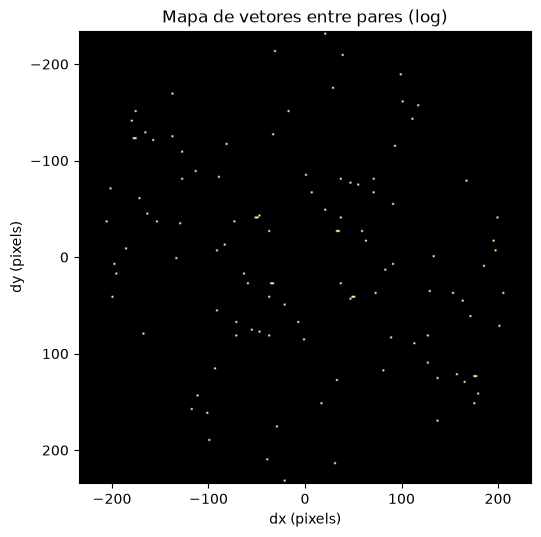

In [35]:
# Calcula o mapa de vetores entre pares de partículas (análogo ao BVM calculado dos dados centralizados)
r_max_pares = 20 * probe_semiangle
mapa_pares = mapa_de_pares(particulas['x'], particulas['y'], r_max_pares, passo=2.0)

fig, eixo = plt.subplots(figsize=(5.5, 5.5))
eixo.imshow(np.log1p(mapa_pares), cmap='inferno', extent=(-r_max_pares, r_max_pares, r_max_pares, -r_max_pares))
eixo.set_title('Mapa de vetores entre pares (log)'); eixo.set_xlabel('dx (pixels)'); eixo.set_ylabel('dy (pixels)')
plt.tight_layout(); plt.show()

# Calibração do tamanho de pixel e distribuição radial

Região de referência: 27.2% da imagem


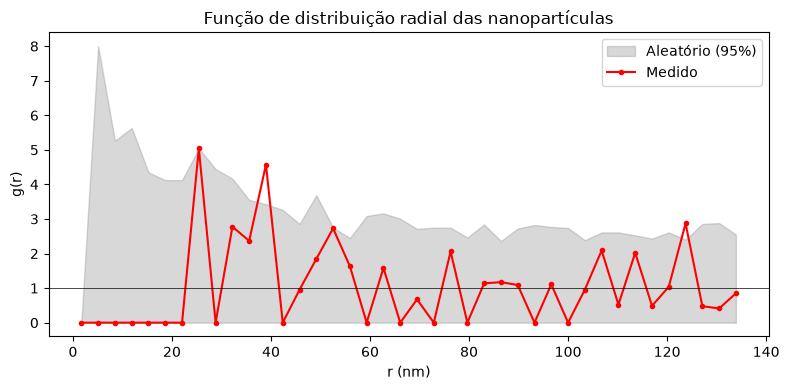

Há agregação (g(r) acima do envelope aleatório) em r entre 39.0 e 123.7 nm


In [36]:
# Calcula e plota a função de distribuição radial g(r) (análoga à integral radial do BVM).
# Referência: distribuição aleatória uniforme (CSR); g = 1 significa ausência de organização espacial.
# Região usada na simulação aleatória: 'especime' (partículas grandes, dilatadas) ou 'imagem' (toda a imagem válida)
regiao_nula = 'especime'

if regiao_nula == 'especime':
    especime = mascara_especime(linear, mascara_roi)
    especime = ndimage.binary_dilation(especime, iterations=int(2 * probe_semiangle))
    regiao = especime & mascara_roi
    if regiao.mean() < 0.01:
        print('Aviso: espécime não identificado; usando a imagem inteira como região de referência.')
        regiao = mascara_roi
else:
    regiao = mascara_roi
print('Região de referência: %.1f%% da imagem' % (100 * regiao.mean()))

dr = probe_semiangle / 2.0
bordas_r = np.arange(0, r_max_pares + dr, dr)
g, g_inf, g_sup = distribuicao_radial(particulas['x'], particulas['y'], regiao, bordas_r, n_sim=200)
r_centro = 0.5 * (bordas_r[:-1] + bordas_r[1:])
fator_nm = tamanho_pixel_roi if tamanho_pixel_roi is not None else 1.0
unidade_r = 'nm' if tamanho_pixel_roi is not None else 'pixels'

ymax = None     # limite superior do eixo y (opcional)
fig, eixo = plt.subplots(figsize=(8, 4))
eixo.fill_between(r_centro * fator_nm, g_inf, g_sup, color='gray', alpha=0.3, label='Aleatório (95%)')
eixo.plot(r_centro * fator_nm, g, 'r-o', markersize=3, label='Medido')
eixo.axhline(1, color='k', linewidth=0.5)
eixo.set_xlabel('r (' + unidade_r + ')'); eixo.set_ylabel('g(r)'); eixo.set_title('Função de distribuição radial das nanopartículas')
if ymax is not None:
    eixo.set_ylim(0, ymax)
eixo.legend(); plt.tight_layout(); plt.show()

# Faixas de r com agregação (g acima do envelope aleatório)
agregado = g > g_sup
if agregado.any():
    print('Há agregação (g(r) acima do envelope aleatório) em r entre %.1f e %.1f %s' % (r_centro[agregado].min() * fator_nm, r_centro[agregado].max() * fator_nm, unidade_r))
else:
    print('Não há desvio significativo em relação a uma distribuição aleatória.')

In [37]:
# (Opcional) Carrega o arquivo da estrutura cristalina do AlN (CIF)
# Esta etapa só faz sentido para imagens com resolução de rede cristalina (ver verificação abaixo).

filepath_cif = file_path + "AlN.cif"
crystal = None
if py4DSTEM is None:
    print('py4DSTEM não está instalado: etapa do arquivo CIF ignorada.')
elif not os.path.isfile(filepath_cif):
    print('Arquivo CIF não encontrado (' + filepath_cif + '): etapa ignorada. Coloque AlN.cif na pasta do notebook para usá-la.')
else:
    crystal = py4DSTEM.process.diffraction.Crystal.from_CIF(filepath_cif)

Arquivo CIF não encontrado (C:\JupyterLab\2-semestre\IP1\Jessika\AlN.cif): etapa ignorada. Coloque AlN.cif na pasta do notebook para usá-la.


In [38]:
# import pymatgen
# crystal = pymatgen.io.cif

In [39]:
# Calcula os fatores de estrutura e verifica se a rede cristalina é resolvida pela imagem
k_max = 1.5       # 1/Angstrom

inv_Ang_per_pixel = None
if tamanho_pixel_roi is not None:
    pixel_Ang = tamanho_pixel_roi * 10.0
    inv_Ang_per_pixel = 1.0 / (dataset.shape[1] * pixel_Ang)
    q_nyquist = 0.5 / pixel_Ang
    print('Limite de Nyquist da imagem: %.3f 1/Angstrom (período mínimo = %.2f nm)' % (q_nyquist, 2 * tamanho_pixel_roi))

if crystal is not None:
    crystal.calculate_structure_factors(
        k_max,
    )
    q_primeira = float(np.min(crystal.g_vec_leng[crystal.g_vec_leng > 0]))
    print('Primeira reflexão do cristal: %.3f 1/Angstrom (d = %.2f Angstrom)' % (q_primeira, 1 / q_primeira))
    if inv_Ang_per_pixel is None:
        print('Sem calibração do pixel: não é possível comparar com os fatores de estrutura.')
    elif q_primeira > q_nyquist:
        print('As reflexões do cristal estão acima do limite de Nyquist da imagem: a rede cristalina NÃO é resolvida nesta imagem.')
        print('(A comparação com o espectro de potência seria sem significado; etapa ignorada.)')
    else:
        # Testa o pixel e sobrepõe os fatores de estrutura ao perfil radial do espectro de potência
        perfil_q = perfil_radial(dp_mean)[:dataset.shape[1] // 2]
        q_exp = np.arange(len(perfil_q)) * inv_Ang_per_pixel
        q_SF = np.linspace(0, k_max, 250)
        I_SF = np.zeros_like(q_SF)
        for a0 in range(crystal.g_vec_leng.shape[0]):
            if np.abs(crystal.g_vec_all[2, a0]) < 0.01:
                idx = np.argmin(np.abs(q_SF - crystal.g_vec_leng[a0]))
                I_SF[idx] += crystal.struct_factors_int[a0]
        I_SF /= np.max(I_SF)
        fig, ax = plt.subplots(figsize=(8, 4))
        ax.semilogy(q_exp, perfil_q * q_exp / np.max(perfil_q * q_exp[1:]))
        ax.set_xlabel('q (1/Å)'); ax.set_xlim([0, min(k_max, q_nyquist)])
        for q_i, i_i in zip(q_SF[I_SF > 0], I_SF[I_SF > 0]):
            ax.axvline(q_i, color='r', alpha=0.4 + 0.6 * i_i)
        plt.tight_layout(); plt.show()

Limite de Nyquist da imagem: 0.086 1/Angstrom (período mínimo = 1.16 nm)


In [40]:
# crystal.plot_structure(
#     zone_axis_lattice=(1,1,0.1),
#     figsize=(6,3),
#     camera_dist = 6,
# )

In [41]:
# Aplica a calibração do tamanho de pixel
calibracao['Q_pixel_size_inv_Ang'] = inv_Ang_per_pixel
print(calibracao)

{'R_pixel_size': 0.5780346820809249, 'R_pixel_units': 'nm', 'Q_pixel_size': 0.0008447265624999999, 'Q_pixel_units': 'nm^-1', 'Q_pixel_size_inv_Ang': 8.447265625e-05}


In [42]:
# # Salva as partículas medidas
# filepath_analysis = file_path + 'AlN_analysis'
# filepath_particulas = filepath_analysis + 'particulas.csv'
# np.savetxt(filepath_particulas, np.column_stack([particulas['x'], particulas['y'], particulas['raio_eq'], particulas['contraste']]),
#            delimiter=',', header='x_px,y_px,raio_eq_px,contraste', comments='')

# Mapeamento automatizado de orientação e morfologia (análogo ao ACOM)

In [43]:
# # Recarrega as partículas medidas, se necessário
# filepath_analysis = file_path + 'AlN_analysis'
# filepath_particulas = filepath_analysis + 'particulas.csv'
# tabela = np.loadtxt(filepath_particulas, delimiter=',', skiprows=1)

Partículas grandes segmentadas: 3


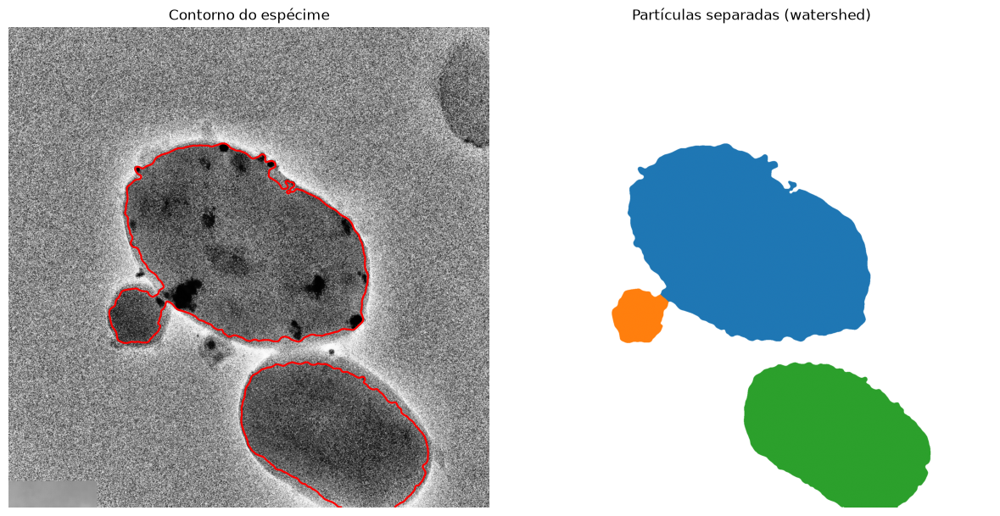

In [44]:
# Cria um plano de orientação para as partículas grandes: segmentação e biblioteca de elipses

plano_orientacao = {
    'angle_step_in_plane': 3,                       # passo angular da biblioteca (graus)
    'razoes': np.arange(1.0, 3.01, 0.1),            # razões de aspecto da biblioteca
    'sigma_segmentacao': 8.0,                       # suavização antes do limiar (pixels)
    'area_min': 20000,                              # área mínima de uma partícula (pixels)
    'distancia_min': 60,                            # distância mínima entre sementes do watershed (pixels)
}

rotulos = segmentar_particulas(
    linear, mascara_roi,
    sigma=plano_orientacao['sigma_segmentacao'],
    area_min=plano_orientacao['area_min'],
    distancia_min=plano_orientacao['distancia_min'],
)
n_particulas = int(rotulos.max())
print('Partículas grandes segmentadas:', n_particulas)

fig, eixos = plt.subplots(1, 2, figsize=(12, 6))
eixos[0].imshow(dataset_visual, cmap='gray', vmin=0, vmax=1)
eixos[0].contour(rotulos > 0, levels=[0.5], colors='r', linewidths=1.5)
eixos[0].set_title('Contorno do espécime'); eixos[0].axis('off')
eixos[1].imshow(np.ma.masked_equal(rotulos, 0), cmap='tab10', vmin=1, vmax=10)
eixos[1].set_title('Partículas separadas (watershed)'); eixos[1].axis('off')
plt.tight_layout(); plt.show()

In [45]:
# Cria um plano de orientação alternativo (faixa restrita de razões de aspecto, passo angular menor)
# plano_orientacao = {
#     'angle_step_in_plane': 1,
#     'razoes': np.arange(1.0, 2.01, 0.05),
#     'sigma_segmentacao': 8.0, 'area_min': 20000, 'distancia_min': 60,
# }

Partícula 1: ângulo = 33°, razão de aspecto = 1.50, IoU = 0.938


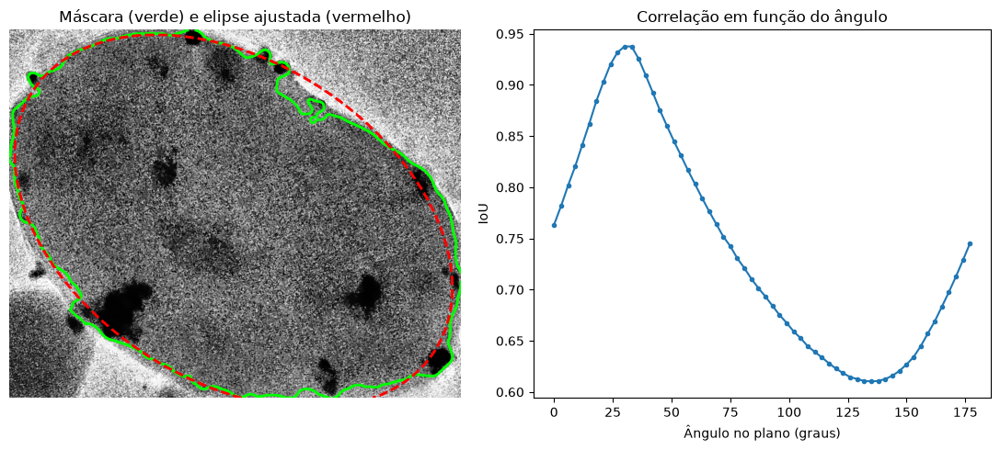

In [46]:
# Testa o casamento (matching) em uma partícula: a maior
areas = np.bincount(rotulos.ravel())[1:]
indice_teste = int(np.argmax(areas)) + 1
mascara_p = rotulos == indice_teste
ys_p, xs_p = np.nonzero(mascara_p)
caixa = (slice(ys_p.min(), ys_p.max() + 1), slice(xs_p.min(), xs_p.max() + 1))

orientation = casar_elipse(
    mascara_p[caixa],
    passo_angulo = plano_orientacao['angle_step_in_plane'],
    razoes = plano_orientacao['razoes'],
)
ang_ajuste, razao_ajuste, iou_ajuste, curva_iou, angulos_lib = orientation
print('Partícula %d: ângulo = %.0f°, razão de aspecto = %.2f, IoU = %.3f' % (indice_teste, np.rad2deg(ang_ajuste), razao_ajuste, iou_ajuste))

# plota as comparações
m_crop = mascara_p[caixa]
area_p = float(m_crop.sum())
cy_p, cx_p = ndimage.center_of_mass(m_crop)
elipse_ajustada = elipse_por_area(m_crop.shape, (cx_p, cy_p), area_p, razao_ajuste, ang_ajuste)

fig, eixos = plt.subplots(1, 2, figsize=(11, 5))
eixos[0].imshow(dataset_visual[caixa], cmap='gray', vmin=0, vmax=1)
eixos[0].contour(m_crop, levels=[0.5], colors='lime', linewidths=2)
eixos[0].contour(elipse_ajustada, levels=[0.5], colors='r', linewidths=2, linestyles='--')
eixos[0].set_title('Máscara (verde) e elipse ajustada (vermelho)'); eixos[0].axis('off')
eixos[1].plot(np.rad2deg(angulos_lib), curva_iou, 'o-', markersize=3)
eixos[1].set_xlabel('Ângulo no plano (graus)'); eixos[1].set_ylabel('IoU'); eixos[1].set_title('Correlação em função do ângulo')
plt.tight_layout(); plt.show()

In [47]:
# Ajusta a orientação em todas as partículas
orientation_map = SimpleNamespace(
    angulo=np.full(rotulos.shape, np.nan, dtype=np.float32),
    razao=np.full(rotulos.shape, np.nan, dtype=np.float32),
    corr=np.full(rotulos.shape, np.nan, dtype=np.float32),
    tabela=[],
)
for i in range(1, n_particulas + 1):
    mascara_i = rotulos == i
    ys_i, xs_i = np.nonzero(mascara_i)
    toca_borda = ys_i.min() == 0 or xs_i.min() == 0 or ys_i.max() == rotulos.shape[0] - 1 or xs_i.max() == rotulos.shape[1] - 1
    ang_i, raz_i, iou_i, _, _ = casar_elipse(
        mascara_i[ys_i.min():ys_i.max() + 1, xs_i.min():xs_i.max() + 1],
        passo_angulo = plano_orientacao['angle_step_in_plane'],
        razoes = plano_orientacao['razoes'],
    )
    orientation_map.angulo[mascara_i] = ang_i
    orientation_map.razao[mascara_i] = raz_i
    orientation_map.corr[mascara_i] = iou_i
    orientation_map.tabela.append((i, float(xs_i.mean()), float(ys_i.mean()), float(mascara_i.sum()), np.rad2deg(ang_i), raz_i, iou_i, bool(toca_borda)))
    print('Partícula %d | área = %d px | ângulo = %3.0f° | razão de aspecto = %.2f | IoU = %.3f%s' % (i, mascara_i.sum(), np.rad2deg(ang_i), raz_i, iou_i, ' | toca a borda' if toca_borda else ''))

Partícula 1 | área = 627838 px | ângulo =  33° | razão de aspecto = 1.50 | IoU = 0.938
Partícula 2 | área = 41326 px | ângulo = 105° | razão de aspecto = 1.10 | IoU = 0.904
Partícula 3 | área = 353455 px | ângulo =  30° | razão de aspecto = 1.60 | IoU = 0.955 | toca a borda


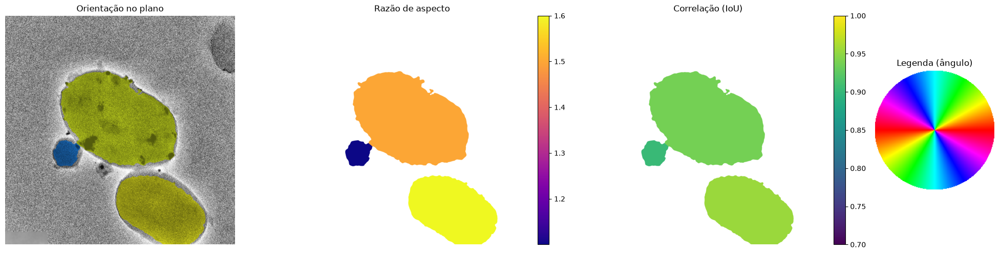

In [48]:
# Plota os mapas de orientação
corr_range = [0.7, 1.0]

fig, eixos = plt.subplots(1, 4, figsize=(20, 5), gridspec_kw={'width_ratios': [1, 1, 1, 0.45]})
fundo_cinza = dataset_visual
# Orientação no plano (cor = ângulo, período de 180 graus), com brilho da imagem
hue = (np.nan_to_num(orientation_map.angulo) % np.pi) / np.pi
cor_ori = hsv_to_rgb(np.dstack([hue, np.full_like(hue, 0.85), 0.35 + 0.65 * fundo_cinza]))
cor_ori[~(rotulos > 0)] = np.dstack([fundo_cinza] * 3)[~(rotulos > 0)]
eixos[0].imshow(cor_ori); eixos[0].set_title('Orientação no plano')
# Razão de aspecto (análogo à inclinação fora do plano)
im1 = eixos[1].imshow(orientation_map.razao, cmap='plasma'); eixos[1].set_title('Razão de aspecto')
plt.colorbar(im1, ax=eixos[1], fraction=0.046, pad=0.04)
# Qualidade do ajuste
im2 = eixos[2].imshow(orientation_map.corr, cmap='viridis', vmin=corr_range[0], vmax=corr_range[1]); eixos[2].set_title('Correlação (IoU)')
plt.colorbar(im2, ax=eixos[2], fraction=0.046, pad=0.04)
for e in eixos[:3]: e.axis('off')
eixos[3].imshow(roda_de_cores_orientacao()); eixos[3].set_title('Legenda (ângulo)'); eixos[3].axis('off')
plt.tight_layout(); plt.show()

In [49]:
# # Plota os mapas de orientação (alternativa: ângulo em escala de cinza)
# plt.figure(figsize=(8, 8))
# plt.imshow(np.rad2deg(orientation_map.angulo), cmap='twilight')
# plt.colorbar(label='Ângulo (graus)')
# plt.title('Inclinação no plano')

# Mapas do tensor de estrutura (análogos aos mapas de deformação)

In [50]:
# Tensor de estrutura local: componentes normalizadas (exx, eyy, exy) e orientação dominante das bordas (theta)

sigma_grad = 2.0         # pixels (escala do gradiente)
sigma_int = 12.0         # pixels (escala da média local)
ts = tensor_de_estrutura(linear, sigma_grad, sigma_int)

# Só mostra onde há energia de gradiente (bordas e estruturas)
mask = (ts['energia'] > np.percentile(ts['energia'][mascara_roi], 70)) & mascara_roi

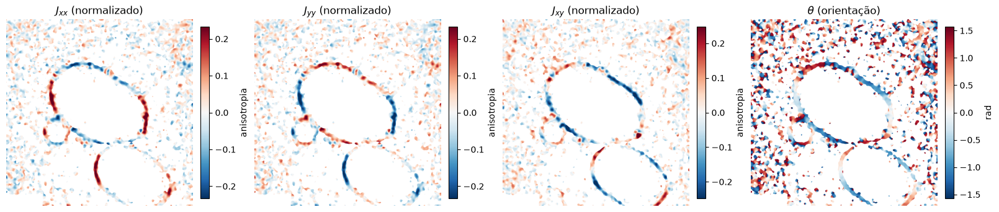

In [51]:
labels = ["exx", "eyy", "exy", "theta"]
titles = [r"$J_{xx}$ (normalizado)", r"$J_{yy}$ (normalizado)", r"$J_{xy}$ (normalizado)", r"$\theta$ (orientação)"]

fig, axs = plt.subplots(1, 4, figsize=(16, 4), constrained_layout=True)

for ax, label, title in zip(axs, labels, titles):
    imdata = ts[label].copy()
    imdata[~mask] = np.nan

    if label == "theta":
        v = np.pi / 2
        unit = "rad"
    else:
        v = np.nanpercentile(np.abs(imdata), 99)
        unit = "anisotropia"

    im = ax.imshow(imdata, cmap="RdBu_r", vmin=-v, vmax=v)
    ax.set_title(title)
    ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label=unit)

plt.show()

# Salvamento dos resultados

In [52]:
# Salva tabelas (CSV) e imagens (float32) na pasta do notebook

base = os.path.splitext(filename)[0]
fator_nm = tamanho_pixel_roi if tamanho_pixel_roi is not None else 1.0
unidade = 'nm' if tamanho_pixel_roi is not None else 'px'

np.savetxt(base + '_particulas.csv',
           np.column_stack([particulas['x'], particulas['y'], particulas['raio_eq'] * fator_nm, particulas['contraste'], particulas['intensidade']]),
           delimiter=',', header='x_px,y_px,raio_eq_' + unidade + ',contraste,intensidade_correlacao', comments='')
np.savetxt(base + '_particulas_grandes.csv', np.array(orientation_map.tabela, dtype=float), delimiter=',',
           header='id,x_px,y_px,area_px,angulo_graus,razao_aspecto,iou,toca_borda', comments='')

imagens_saida = {
    base + '_PLUS_SCIENTIFIC.tif': dataset_scientific,
    base + '_PLUS_VISUAL.tif': dataset_visual,
    base + '_CONTRASTE_CENTRO_PERIFERIA.tif': contraste_centro_periferia,
    base + '_ROTULOS.tif': rotulos.astype(np.int32),
}
for caminho_saida, imagem_saida in imagens_saida.items():
    tifffile.imwrite(caminho_saida, np.asarray(imagem_saida), photometric='minisblack')

print('ARQUIVOS SALVOS:')
for caminho_saida in [base + '_particulas.csv', base + '_particulas_grandes.csv'] + list(imagens_saida):
    print(caminho_saida)

ARQUIVOS SALVOS:
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_particulas.csv
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_particulas_grandes.csv
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_PLUS_SCIENTIFIC.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_PLUS_VISUAL.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_CONTRASTE_CENTRO_PERIFERIA.tif
C:\JupyterLab\2-semestre\IP1\Jessika\CG_059_ROTULOS.tif
